# Proyecto 01: Retail Intelligence (RetailVenture C.A.)
## A4: Evaluación de Marketing, Conversión, Elasticidad de Descuentos y Retorno de Inversión

**Autores:** Daniel, Andrés y Samuel (Grupo 3)  
**Materia:** Tópicos Especiales para la Gestión de Datos · UCAB  
**Profesor:** Armen Djenanian  

---

### Preguntas de Investigación y Objetivos del Análisis
La gerencia general de **RetailVenture C.A.** reporta una **pérdida de efectividad publicitaria**, señalando una reducción de la tasa de conversión en los últimos 18 meses (del 22% al 11% en el relato ejecutivo). 

En esta actividad se formulan y responden rigurosamente las siguientes preguntas de investigación con base en los microdatos empíricos:
1. **A4.1:** ¿Cuál es la tasa real de conversión publicitaria por canal, tipo de campaña y segmento, y cómo evolucionó temporalmente? ¿Qué brecha existe entre la conversión declarada en marketing y la compra validada a 30 días?
2. **A4.2:** ¿Existe evidencia de que mayores descuentos aumenten sistemáticamente la conversión, o se observan rendimientos decrecientes o estancamiento en niveles superiores al 20%?
3. **A4.3:** ¿Se asocia la no conversión a fricciones operativas de post-venta (quejas en CRM o devoluciones), o existen explicaciones alternativas fundamentadas en datos?
4. **A4.4:** Bajo una atribución Last-Touch estricta a 30 días (sin compras duplicadas), ¿cuál es el retorno bruto contable frente al **ROI incremental real** evaluado mediante remuestreo bootstrap e inferencia contrafactual?
5. **Resumen Ejecutivo:** Tabla consolidada de métricas maestras de marketing gobernadas por variables dinámicas para su consumo en el dashboard gerencial A5.


In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint

# Configuración visual ejecutiva
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Directorio de datos limpios
DATA_PATH = Path("../data/clean")

# Carga de datasets limpios
campanas = pd.read_csv(DATA_PATH / "campanas_limpia.csv", parse_dates=["fecha_envio"])
transacciones = pd.read_csv(DATA_PATH / "transacciones_maestra.csv", parse_dates=["fecha"])
clientes = pd.read_csv(DATA_PATH / "clientes_maestra.csv")
crm = pd.read_csv(DATA_PATH / "crm_limpio.csv", parse_dates=["fecha"])

print(f"Campañas cargadas: {len(campanas):,}")
print(f"Transacciones operativas: {len(transacciones):,}")
print(f"Clientes maestros: {len(clientes):,}")
print(f"Interacciones CRM: {len(crm):,}")


Campañas cargadas: 8,820
Transacciones operativas: 50,000
Clientes maestros: 8,000
Interacciones CRM: 4,684


---
## A4.1 Medición Multidimensional de Conversión, Calidad del Flag y Evolución Temporal

Auditamos la efectividad publicitaria distinguiendo formalmente:
- **Conversión Declarada (`convertido`):** Flag auto-reportado por el sistema de marketing.
- **Conversión Validada (`convertido_validado_30d`):** Registro auditable de si el cliente ejecutó al menos una compra en la ventana de 30 días posteriores al envío.


In [2]:
# 1. Auditoría de calidad del flag declarado (C5a)
# ¿Estar marcado como convertido=1 se asocia con una compra real en los 30 días posteriores al envío?
# Se usan los envíos con ventana completa (antes de 2024-12-01).
from statsmodels.stats.proportion import proportions_ztest

camp_elegible_all = campanas[campanas['fecha_envio'] < '2024-12-01'].copy()
tx_por_cliente_fechas = {cli: g['fecha'].values for cli, g in transacciones.groupby('cliente_id')}

v = camp_elegible_all[['campana_id', 'cliente_id', 'fecha_envio']].merge(
    transacciones[['cliente_id', 'fecha']], on='cliente_id')
v = v[(v['fecha'] >= v['fecha_envio']) & (v['fecha'] <= v['fecha_envio'] + pd.Timedelta(days=30))]
camp_elegible_all['compro_real_30d'] = camp_elegible_all['campana_id'].isin(v['campana_id'])

g1 = camp_elegible_all[camp_elegible_all['convertido'] == 1]['compro_real_30d']
g0 = camp_elegible_all[camp_elegible_all['convertido'] == 0]['compro_real_30d']
p_compra_conv1, p_compra_conv0 = g1.mean() * 100, g0.mean() * 100
n_conv_decl, n_conv_con_compra = len(g1), int(g1.sum())
dif_flag = (g1.mean() - g0.mean())
ee_flag = np.sqrt(g1.mean() * (1 - g1.mean()) / len(g1) + g0.mean() * (1 - g0.mean()) / len(g0))
z_flag, p_flag = proportions_ztest([g1.sum(), g0.sum()], [len(g1), len(g0)])

print("--- AUDITORÍA DE CONFIABILIDAD DEL FLAG 'convertido' (C5a) ---")
print(f"• Conversiones declaradas con compra real en 30 días: {n_conv_con_compra:,} de {n_conv_decl:,} ({p_compra_conv1:.2f}%)")
print(f"• P(compra real en 30d | convertido = 1): {p_compra_conv1:.2f}% (n = {len(g1):,})")
print(f"• P(compra real en 30d | convertido = 0): {p_compra_conv0:.2f}% (n = {len(g0):,})")
print(f"• Diferencia: {dif_flag*100:+.2f} p.p., IC 95% [{(dif_flag - 1.96*ee_flag)*100:+.2f}, {(dif_flag + 1.96*ee_flag)*100:+.2f}], "
      f"z = {z_flag:.2f}, p = {p_flag:.3f}")
if p_flag < 0.05:
    print(f"• Las dos probabilidades difieren al 5%, pero la diferencia es pequeña: {100 - p_compra_conv1:.1f}% de las "
          "conversiones declaradas no tiene ninguna compra en los 30 días siguientes.")
else:
    print(f"• No se detecta diferencia: un envío marcado como convertido no tiene más probabilidad de compra real que uno no "
          f"marcado. {100 - p_compra_conv1:.1f}% de las conversiones declaradas no tiene ninguna compra en los 30 días siguientes.")
print("• Por eso el análisis reporta siempre las dos métricas: declarada y validada.")

--- AUDITORÍA DE CONFIABILIDAD DEL FLAG 'convertido' (C5a) ---
• Conversiones declaradas con compra real en 30 días: 177 de 776 (22.81%)
• P(compra real en 30d | convertido = 1): 22.81% (n = 776)
• P(compra real en 30d | convertido = 0): 20.45% (n = 7,674)
• Diferencia: +2.36 p.p., IC 95% [-0.72, +5.45], z = 1.55, p = 0.121
• No se detecta diferencia: un envío marcado como convertido no tiene más probabilidad de compra real que uno no marcado. 77.2% de las conversiones declaradas no tiene ninguna compra en los 30 días siguientes.
• Por eso el análisis reporta siempre las dos métricas: declarada y validada.


In [3]:
# 2. Conversión por Tipo de Campaña y Segmento (Declarada vs Validada)
conv_tipo = campanas.groupby('tipo_campana').agg(
    envios=('campana_id', 'count'),
    conv_declarada=('convertido', 'sum'),
    tasa_declarada=('convertido', lambda s: s.mean() * 100),
    conv_validada=('convertido_validado_30d', 'sum'),
    tasa_validada=('convertido_validado_30d', lambda s: s.mean() * 100),
    descuento_medio=('descuento_ofrecido', lambda s: s.mean() * 100)
).reset_index().sort_values('tasa_declarada', ascending=False)

print("CONVERSIÓN POR TIPO DE CAMPAÑA:")
display(conv_tipo.round(2))

conv_seg = campanas.groupby('segmento').agg(
    envios=('campana_id', 'count'),
    conv_declarada=('convertido', 'sum'),
    tasa_declarada=('convertido', lambda s: s.mean() * 100),
    conv_validada=('convertido_validado_30d', 'sum'),
    tasa_validada=('convertido_validado_30d', lambda s: s.mean() * 100),
    descuento_medio=('descuento_ofrecido', lambda s: s.mean() * 100)
).reset_index().sort_values('tasa_declarada', ascending=False)

print("\nCONVERSIÓN POR SEGMENTO DE CLIENTE:")
display(conv_seg.round(2))


CONVERSIÓN POR TIPO DE CAMPAÑA:


,tipo_campana,envios,conv_declarada,tasa_declarada,conv_validada,tasa_validada,descuento_medio
1,email_fidelizacion,1748,174,9.95,43,2.46,12.59
2,push_reactivacion,1768,162,9.16,34,1.92,12.31
0,email_descuento,3099,274,8.84,67,2.16,12.48
4,social_ads,860,75,8.72,13,1.51,12.52
3,sms_oferta_flash,1345,112,8.33,22,1.64,12.19



CONVERSIÓN POR SEGMENTO DE CLIENTE:


,segmento,envios,conv_declarada,tasa_declarada,conv_validada,tasa_validada,descuento_medio
4,Premium,877,120,13.68,65,7.41,12.64
3,Nuevo,933,99,10.61,4,0.43,12.25
0,Esporádico,3118,297,9.53,32,1.03,12.50
1,Frecuente,2654,213,8.03,76,2.86,12.38
2,Inactivo,1238,68,5.49,2,0.16,12.34


In [4]:
# 3. Combinaciones Clave (Tipo x Canal x Segmento) con Mínimo 100 Envíos e IC Wilson (R7 / C15)
comb = campanas.groupby(['tipo_campana', 'canal_campana', 'segmento']).agg(
    envios=('campana_id', 'count'),
    conv_decl=('convertido', 'sum'),
    conv_val=('convertido_validado_30d', 'sum')
).reset_index()

comb_100 = comb[comb['envios'] >= 100].copy()
comb_100['tasa_declarada'] = (comb_100['conv_decl'] / comb_100['envios']) * 100
comb_100['tasa_validada'] = (comb_100['conv_val'] / comb_100['envios']) * 100

ci_decl = [proportion_confint(k, n, alpha=0.05, method='wilson') for k, n in zip(comb_100['conv_decl'], comb_100['envios'])]
ci_val = [proportion_confint(k, n, alpha=0.05, method='wilson') for k, n in zip(comb_100['conv_val'], comb_100['envios'])]

comb_100['ic_95_declarada'] = [f"[{l*100:.1f}%, {u*100:.1f}%]" for l, u in ci_decl]
comb_100['ic_95_validada'] = [f"[{l*100:.1f}%, {u*100:.1f}%]" for l, u in ci_val]

comb_100 = comb_100.sort_values('tasa_declarada', ascending=False)

print(f"COMBINACIONES CON >= 100 ENVÍOS ({len(comb_100)} combinaciones elegibles de {len(comb)} totales):")
display(comb_100[['tipo_campana', 'canal_campana', 'segmento', 'envios', 
                  'tasa_declarada', 'ic_95_declarada', 'tasa_validada', 'ic_95_validada']].round(2))

# Resaltar la fuga en segmentos Nuevo e Inactivo
envios_nuevo_inactivo = campanas[campanas['segmento'].isin(['Nuevo', 'Inactivo'])].shape[0]
pct_nuevo_inactivo = (envios_nuevo_inactivo / len(campanas)) * 100
val_nuevo = conv_seg.loc[conv_seg['segmento']=='Nuevo', 'tasa_validada'].values[0]
val_inactivo = conv_seg.loc[conv_seg['segmento']=='Inactivo', 'tasa_validada'].values[0]

print(f"\n• Auditoría de Eficiencia de Segmentación:")
print(f"  Los segmentos 'Nuevo' e 'Inactivo' recibieron {envios_nuevo_inactivo:,} envíos ({pct_nuevo_inactivo:.1f}% de la pauta total),")
print(f"  alcanzando tasas de conversión validadas de apenas {val_nuevo:.2f}% y {val_inactivo:.2f}%, respectivamente.")
print(f"  Hipótesis respaldada por datos: Gran parte del presupuesto publicitario se asigna a contactos fríos o desconectados")
print(f"  donde el incentivo digital no se materializa en compras operativas.")


COMBINACIONES CON >= 100 ENVÍOS (24 combinaciones elegibles de 25 totales):


,tipo_campana,canal_campana,segmento,envios,tasa_declarada,ic_95_declarada,tasa_validada,ic_95_validada
9,email_fidelizacion,email,Premium,166,15.66,"[10.9%, 22.0%]",9.04,"[5.6%, 14.4%]"
14,push_reactivacion,push_app,Premium,189,15.34,"[10.9%, 21.2%]",6.88,"[4.1%, 11.4%]"
23,social_ads,redes_sociales,Nuevo,100,13.00,"[7.8%, 21.0%]",0.00,"[0.0%, 3.7%]"
4,email_descuento,email,Premium,321,12.77,"[9.6%, 16.9%]",8.41,"[5.8%, 12.0%]"
8,email_fidelizacion,email,Nuevo,181,11.60,"[7.7%, 17.1%]",0.00,"[0.0%, 2.1%]"
18,sms_oferta_flash,sms,Nuevo,153,11.11,"[7.1%, 17.1%]",0.00,"[0.0%, 2.4%]"
13,push_reactivacion,push_app,Nuevo,165,10.91,"[7.0%, 16.6%]",0.61,"[0.1%, 3.4%]"
5,email_fidelizacion,email,Esporádico,619,10.18,"[8.0%, 12.8%]",0.97,"[0.4%, 2.1%]"
0,email_descuento,email,Esporádico,1084,9.87,"[8.2%, 11.8%]",1.11,"[0.6%, 1.9%]"
15,sms_oferta_flash,sms,Esporádico,474,9.49,"[7.2%, 12.5%]",1.27,"[0.6%, 2.7%]"



• Auditoría de Eficiencia de Segmentación:
  Los segmentos 'Nuevo' e 'Inactivo' recibieron 2,171 envíos (24.6% de la pauta total),
  alcanzando tasas de conversión validadas de apenas 0.43% y 0.16%, respectivamente.
  Hipótesis respaldada por datos: Gran parte del presupuesto publicitario se asigna a contactos fríos o desconectados
  donde el incentivo digital no se materializa en compras operativas.


In [5]:
# 4. Tendencia temporal semestral y trimestral, declarada y validada (C5b, C5e)
# La conversión validada exige 30 días de observación: los envíos de diciembre 2024 tienen la ventana
# incompleta, por eso también se muestra la validada solo con envíos de ventana completa.
campanas['anio_trimestre'] = campanas['fecha_envio'].dt.to_period('Q').astype(str)
campanas['semestre'] = campanas['fecha_envio'].dt.year.astype(str) + '-S' + ((campanas['fecha_envio'].dt.month - 1) // 6 + 1).astype(str)
campanas['ventana_completa'] = campanas['fecha_envio'] < '2024-12-01'


def tendencia(col_periodo):
    t = campanas.groupby(col_periodo).agg(
        total_envios=('campana_id', 'count'),
        conv_declarada_pct=('convertido', lambda s: s.mean() * 100),
        conv_validada_pct=('convertido_validado_30d', lambda s: s.mean() * 100),
    )
    t['conv_validada_ventana_completa_pct'] = (campanas[campanas['ventana_completa']]
                                               .groupby(col_periodo)['convertido_validado_30d'].mean() * 100)
    return t.reset_index()


conv_sem = tendencia('semestre')
conv_trim = tendencia('anio_trimestre')
print("EVOLUCIÓN TEMPORAL SEMESTRAL:")
display(conv_sem.round(2))
print("\nEVOLUCIÓN TEMPORAL TRIMESTRAL:")
display(conv_trim.round(2))

primer_sem, ultimo_sem = conv_sem['semestre'].iloc[0], conv_sem['semestre'].iloc[-1]
s_ini, s_fin = conv_sem.iloc[0], conv_sem.iloc[-1]
decl_s1, decl_s4 = s_ini['conv_declarada_pct'], s_fin['conv_declarada_pct']
val_s1, val_s4 = s_ini['conv_validada_pct'], s_fin['conv_validada_pct']
valc_s4 = s_fin['conv_validada_ventana_completa_pct']
caida_relativa = (decl_s4 - decl_s1) / decl_s1 * 100
caida_relativa_val = (val_s4 - val_s1) / val_s1 * 100
caida_relativa_valc = (valc_s4 - val_s1) / val_s1 * 100

print(f"\n• Declarada: {decl_s1:.2f}% ({primer_sem}) → {decl_s4:.2f}% ({ultimo_sem}), variación relativa {caida_relativa:+.1f}%.")
print(f"• Validada: {val_s1:.2f}% → {val_s4:.2f}%, variación relativa {caida_relativa_val:+.1f}% "
      f"({valc_s4:.2f}% y {caida_relativa_valc:+.1f}% si se excluyen los envíos de diciembre 2024 con ventana incompleta).")
CONV_ENUNCIADO_INI, CONV_ENUNCIADO_FIN = 22.0, 11.0          # cifras del enunciado del proyecto
caida_enunciado = (CONV_ENUNCIADO_FIN - CONV_ENUNCIADO_INI) / CONV_ENUNCIADO_INI * 100
similar = abs(caida_relativa - caida_enunciado) <= 10
print(f"• Frente al enunciado (caída del {CONV_ENUNCIADO_INI:.0f}% al {CONV_ENUNCIADO_FIN:.0f}%): los niveles difieren (los datos "
      f"parten de {decl_s1:.1f}%), pero la caída relativa de la declarada ({caida_relativa:+.1f}%) es de magnitud "
      + ("similar" if similar else "distinta") + f" a la del enunciado ({caida_enunciado:+.0f}%).")

EVOLUCIÓN TEMPORAL SEMESTRAL:


,semestre,total_envios,conv_declarada_pct,conv_validada_pct,conv_validada_ventana_completa_pct
0,2023-S1,2168,11.81,2.91,2.91
1,2023-S2,2200,10.68,2.09,2.09
2,2024-S1,2210,7.38,1.86,1.86
3,2024-S2,2242,6.38,1.29,1.44



EVOLUCIÓN TEMPORAL TRIMESTRAL:


,anio_trimestre,total_envios,conv_declarada_pct,conv_validada_pct,conv_validada_ventana_completa_pct
0,2023Q1,1055,11.28,3.13,3.13
1,2023Q2,1113,12.31,2.70,2.70
2,2023Q3,1094,11.15,2.29,2.29
3,2023Q4,1106,10.22,1.90,1.90
4,2024Q1,1082,7.95,1.85,1.85
5,2024Q2,1128,6.83,1.86,1.86
6,2024Q3,1167,7.11,1.63,1.63
7,2024Q4,1075,5.58,0.93,1.13



• Declarada: 11.81% (2023-S1) → 6.38% (2024-S2), variación relativa -46.0%.
• Validada: 2.91% → 1.29%, variación relativa -55.5% (1.44% y -50.4% si se excluyen los envíos de diciembre 2024 con ventana incompleta).
• Frente al enunciado (caída del 22% al 11%): los niveles difieren (los datos parten de 11.8%), pero la caída relativa de la declarada (-46.0%) es de magnitud similar a la del enunciado (-50%).


In [6]:
# 5. Descomposición de la caída de conversión: ¿cambió la mezcla de envíos o cae dentro de cada grupo? (C5d)
# Variación total = Σ w₂·r₂ − Σ w₁·r₁ = efecto mezcla + efecto dentro del grupo
#   efecto mezcla        = Σ (w₂ − w₁) · r₁     (cambio en la participación de cada grupo en los envíos)
#   efecto dentro grupo  = Σ w₂ · (r₂ − r₁)     (cambio de la tasa dentro de cada grupo)
# Para la validada se usan solo envíos con ventana completa.


def descomponer(dim, col_tasa, df):
    base = df[df['semestre'].isin([primer_sem, ultimo_sem])]
    t = base.groupby(['semestre', dim]).agg(envios=('campana_id', 'count'), tasa=(col_tasa, 'mean')).reset_index()
    t['peso'] = t['envios'] / t.groupby('semestre')['envios'].transform('sum')
    a = t[t['semestre'] == primer_sem].set_index(dim)
    b = t[t['semestre'] == ultimo_sem].set_index(dim)
    tab = pd.DataFrame({
        f'envios {primer_sem}': a['envios'], f'envios {ultimo_sem}': b['envios'],
        f'peso {primer_sem} %': a['peso'] * 100, f'peso {ultimo_sem} %': b['peso'] * 100,
        f'tasa {primer_sem} %': a['tasa'] * 100, f'tasa {ultimo_sem} %': b['tasa'] * 100,
    })
    tab['efecto mezcla (p.p.)'] = (b['peso'] - a['peso']) * a['tasa'] * 100
    tab['efecto dentro (p.p.)'] = b['peso'] * (b['tasa'] - a['tasa']) * 100
    total = (b['peso'] * b['tasa']).sum() * 100 - (a['peso'] * a['tasa']).sum() * 100
    return tab, total, tab['efecto mezcla (p.p.)'].sum(), tab['efecto dentro (p.p.)'].sum()


descomp_c5 = []
for dim in ['segmento', 'tipo_campana']:
    for etiqueta, col, df in [('declarada', 'convertido', campanas),
                              ('validada (ventana completa)', 'convertido_validado_30d', campanas[campanas['ventana_completa']])]:
        tab, total, mezcla, dentro = descomponer(dim, col, df)
        print(f"\n--- {dim.upper()} × SEMESTRE, conversión {etiqueta}: {primer_sem} vs {ultimo_sem} ---")
        display(tab.round(2))
        print(f"• Variación total {total:+.2f} p.p. = mezcla {mezcla:+.2f} p.p. + dentro de los grupos {dentro:+.2f} p.p.")
        descomp_c5.append({'dimensión': dim, 'métrica': etiqueta, 'variación total (p.p.)': total,
                           'efecto mezcla (p.p.)': mezcla, 'efecto dentro (p.p.)': dentro})

descomp_c5 = pd.DataFrame(descomp_c5)
print("\nRESUMEN DE LA DESCOMPOSICIÓN:")
display(descomp_c5.round(2))
for _, r in descomp_c5.iterrows():
    proporcion = r['efecto dentro (p.p.)'] / r['variación total (p.p.)'] * 100 if r['variación total (p.p.)'] else float('nan')
    print(f"• {r['dimensión']}, {r['métrica']}: el {int(round(proporcion))}% de la variación ocurre dentro de los grupos "
          f"y el {int(round(100 - proporcion))}% se debe al cambio de mezcla de envíos.")


--- SEGMENTO × SEMESTRE, conversión declarada: 2023-S1 vs 2024-S2 ---


,envios 2023-S1,envios 2024-S2,peso 2023-S1 %,peso 2024-S2 %,tasa 2023-S1 %,tasa 2024-S2 %,efecto mezcla (p.p.),efecto dentro (p.p.)
segmento,,,,,,,,
Esporádico,754,806,34.78,35.95,12.73,6.58,0.15,-2.21
Frecuente,634,684,29.24,30.51,10.09,5.85,0.13,-1.30
Inactivo,303,327,13.98,14.59,5.94,4.89,0.04,-0.15
Nuevo,233,219,10.75,9.77,13.73,7.31,-0.13,-0.63
Premium,244,206,11.25,9.19,18.85,8.74,-0.39,-0.93


• Variación total -5.43 p.p. = mezcla -0.21 p.p. + dentro de los grupos -5.22 p.p.

--- SEGMENTO × SEMESTRE, conversión validada (ventana completa): 2023-S1 vs 2024-S2 ---


,envios 2023-S1,envios 2024-S2,peso 2023-S1 %,peso 2024-S2 %,tasa 2023-S1 %,tasa 2024-S2 %,efecto mezcla (p.p.),efecto dentro (p.p.)
segmento,,,,,,,,
Esporádico,754,686,34.78,36.65,1.06,0.73,0.02,-0.12
Frecuente,634,561,29.24,29.97,3.63,2.67,0.03,-0.29
Inactivo,303,272,13.98,14.53,0.33,0.00,0.00,-0.05
Nuevo,233,183,10.75,9.78,0.86,0.00,-0.01,-0.08
Premium,244,170,11.25,9.08,11.89,4.12,-0.26,-0.71


• Variación total -1.46 p.p. = mezcla -0.22 p.p. + dentro de los grupos -1.24 p.p.

--- TIPO_CAMPANA × SEMESTRE, conversión declarada: 2023-S1 vs 2024-S2 ---


...

• Variación total -5.43 p.p. = mezcla -0.01 p.p. + dentro de los grupos -5.42 p.p.

--- TIPO_CAMPANA × SEMESTRE, conversión validada (ventana completa): 2023-S1 vs 2024-S2 ---


,envios 2023-S1,envios 2024-S2,peso 2023-S1 %,peso 2024-S2 %,tasa 2023-S1 %,tasa 2024-S2 %,efecto mezcla (p.p.),efecto dentro (p.p.)
tipo_campana,,,,,,,,
email_descuento,789,648,36.39,34.62,3.17,0.77,-0.06,-0.83
email_fidelizacion,411,366,18.96,19.55,3.41,2.46,0.02,-0.19
push_reactivacion,409,379,18.87,20.25,2.93,1.85,0.04,-0.22
sms_oferta_flash,331,295,15.27,15.76,2.42,1.36,0.01,-0.17
social_ads,228,184,10.52,9.83,1.75,1.09,-0.01,-0.07


• Variación total -1.46 p.p. = mezcla +0.00 p.p. + dentro de los grupos -1.47 p.p.

RESUMEN DE LA DESCOMPOSICIÓN:


,dimensión,métrica,variación total (p.p.),efecto mezcla (p.p.),efecto dentro (p.p.)
0,segmento,declarada,-5.43,-0.21,-5.22
1,segmento,validada (ventana completa),-1.46,-0.22,-1.24
2,tipo_campana,declarada,-5.43,-0.01,-5.42
3,tipo_campana,validada (ventana completa),-1.46,0.00,-1.47


• segmento, declarada: el 96% de la variación ocurre dentro de los grupos y el 4% se debe al cambio de mezcla de envíos.
• segmento, validada (ventana completa): el 85% de la variación ocurre dentro de los grupos y el 15% se debe al cambio de mezcla de envíos.
• tipo_campana, declarada: el 100% de la variación ocurre dentro de los grupos y el 0% se debe al cambio de mezcla de envíos.
• tipo_campana, validada (ventana completa): el 100% de la variación ocurre dentro de los grupos y el 0% se debe al cambio de mezcla de envíos.


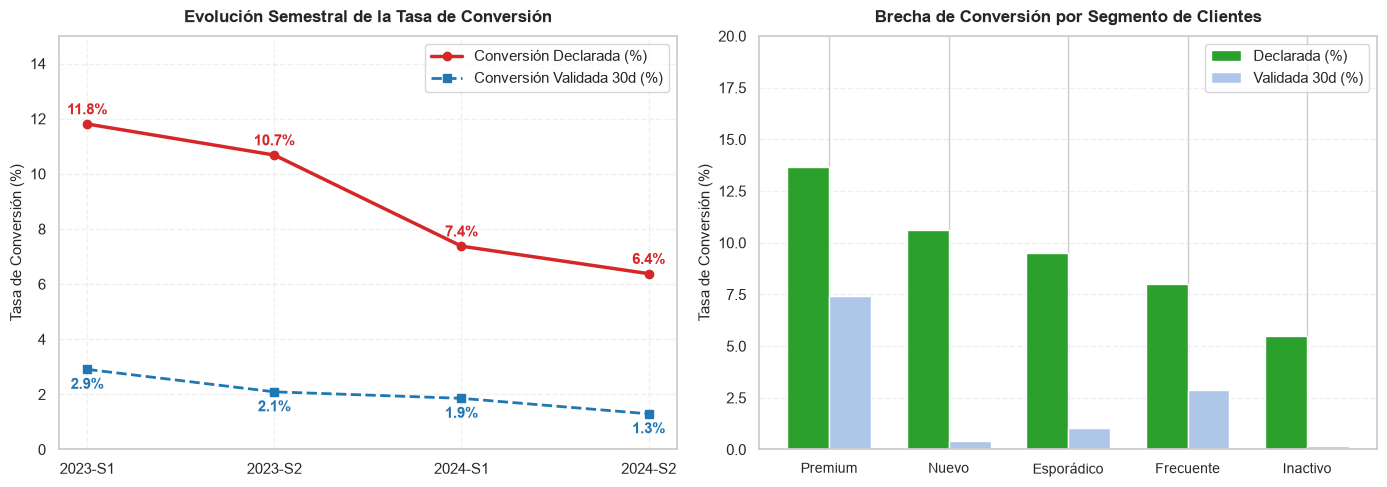

In [7]:
# Gráfica de Tendencia Temporal y Brecha Declarada vs Validada
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Evolución Semestral
ax1.plot(conv_sem['semestre'], conv_sem['conv_declarada_pct'], marker='o', lw=2.5, color='#D62728', label='Conversión Declarada (%)')
ax1.plot(conv_sem['semestre'], conv_sem['conv_validada_pct'], marker='s', lw=2.0, color='#1F77B4', linestyle='--', label='Conversión Validada 30d (%)')
ax1.set_title('Evolución Semestral de la Tasa de Conversión', fontsize=12, fontweight='bold', pad=10)
ax1.set_ylabel('Tasa de Conversión (%)', fontsize=11)
ax1.set_ylim(0, 15)
ax1.grid(alpha=0.3, linestyle='--')
ax1.legend(frameon=True)

for i, txt in enumerate(conv_sem['conv_declarada_pct']):
    ax1.annotate(f"{txt:.1f}%", (i, txt), textcoords="offset points", xytext=(0, 7), ha='center', fontweight='bold', color='#D62728')
for i, txt in enumerate(conv_sem['conv_validada_pct']):
    ax1.annotate(f"{txt:.1f}%", (i, txt), textcoords="offset points", xytext=(0, -14), ha='center', fontweight='bold', color='#1F77B4')

# Subplot 2: Segmento (Declarada vs Validada)
x = np.arange(len(conv_seg))
width = 0.35
ax2.bar(x - width/2, conv_seg['tasa_declarada'], width, label='Declarada (%)', color='#2CA02C')
ax2.bar(x + width/2, conv_seg['tasa_validada'], width, label='Validada 30d (%)', color='#AEC7E8')
ax2.set_title('Brecha de Conversión por Segmento de Clientes', fontsize=12, fontweight='bold', pad=10)
ax2.set_xticks(x)
ax2.set_xticklabels(conv_seg['segmento'], fontsize=10)
ax2.set_ylabel('Tasa de Conversión (%)', fontsize=11)
ax2.set_ylim(0, 20)
ax2.grid(axis='y', alpha=0.3, linestyle='--')
ax2.legend(frameon=True)

plt.tight_layout()
plt.show()


---
## A4.2 Elasticidad de Incentivos: Análisis de Descuentos Ofrecidos y Rendimientos Marginales

Evaluamos si ofrecer descuentos progresivamente mayores (5% a 25%) incrementa sistemáticamente la conversión, o si se aprecian rendimientos decrecientes al superar el 20%.


In [8]:
# 1. Matrices Segmento x Descuento con Tamaño Muestral (N) y Conversión Validada (C4)
piv_decl = campanas.pivot_table(index='segmento', columns='descuento_ofrecido', values='convertido', aggfunc=lambda s: s.mean() * 100)
piv_n = campanas.pivot_table(index='segmento', columns='descuento_ofrecido', values='campana_id', aggfunc='count')
piv_val = campanas.pivot_table(index='segmento', columns='descuento_ofrecido', values='convertido_validado_30d', aggfunc=lambda s: s.mean() * 100)

print("TASA DE CONVERSIÓN DECLARADA (%) POR SEGMENTO Y DESCUENTO:")
display(piv_decl.round(1))

print("\nTAMAÑO MUESTRAL (N ENVÍOS) POR CELDA:")
display(piv_n)

print("\nTASA DE CONVERSIÓN VALIDADA 30D (%) POR SEGMENTO Y DESCUENTO:")
display(piv_val.round(1))


TASA DE CONVERSIÓN DECLARADA (%) POR SEGMENTO Y DESCUENTO:


descuento_ofrecido,0.00,0.05,0.10,0.15,0.20,0.25
segmento,,,,,,
Esporádico,5.9,7.2,10.2,11.7,12.0,10.4
Frecuente,3.7,5.9,8.4,10.0,9.6,11.0
Inactivo,1.5,2.0,6.6,4.8,9.4,8.6
Nuevo,7.3,10.5,8.9,12.0,10.3,15.2
Premium,10.6,11.7,8.6,15.7,18.8,16.5



TAMAÑO MUESTRAL (N ENVÍOS) POR CELDA:


descuento_ofrecido,0.00,0.05,0.10,0.15,0.20,0.25
segmento,,,,,,
Esporádico,525,541,490,513,510,539
Frecuente,462,457,430,422,428,455
Inactivo,206,199,227,208,212,186
Nuevo,165,153,157,158,155,145
Premium,123,154,152,166,149,133



TASA DE CONVERSIÓN VALIDADA 30D (%) POR SEGMENTO Y DESCUENTO:


descuento_ofrecido,0.00,0.05,0.10,0.15,0.20,0.25
segmento,,,,,,
Esporádico,0.8,0.7,1.2,1.0,1.2,1.3
Frecuente,2.2,2.4,2.8,2.8,2.3,4.6
Inactivo,0.0,0.0,0.0,0.0,0.9,0.0
Nuevo,0.0,0.7,0.0,1.3,0.6,0.0
Premium,6.5,7.8,2.6,7.2,10.1,10.5


In [9]:
# 2. Regresión logística con descuento categórico y contraste 25% vs 20% controlando por segmento (C4c, C4d)
FORMULA_C4 = ('{y} ~ C(descuento_ofrecido) + C(segmento, Treatment(reference="Esporádico"))'
              ' + C(tipo_campana, Treatment(reference="email_descuento"))')


def nombre_legible(param):
    if param == 'Intercept':
        return 'Intercepto (0%, Esporádico, email_descuento)'
    nivel = param.split('[T.')[-1].rstrip(']')
    if param.startswith('C(descuento_ofrecido)'):
        return f"Descuento {float(nivel)*100:.0f}% (vs 0%)"
    if param.startswith('C(segmento'):
        return f"Segmento {nivel} (vs Esporádico)"
    return f"Tipo {nivel} (vs email_descuento)"


def ajustar_logit(y):
    mod = smf.logit(FORMULA_C4.format(y=y), data=campanas).fit(disp=False)
    ic = mod.conf_int()
    tabla = pd.DataFrame({'Odds ratio': np.exp(mod.params), 'IC 95% inf': np.exp(ic[0]),
                          'IC 95% sup': np.exp(ic[1]), 'p-valor': mod.pvalues})
    tabla.index = [nombre_legible(p) for p in tabla.index]
    # Contraste 25% vs 20% dentro del mismo modelo (controla segmento y tipo)
    nombres = list(mod.params.index)
    r = np.zeros(len(nombres))
    r[nombres.index('C(descuento_ofrecido)[T.0.25]')] = 1
    r[nombres.index('C(descuento_ofrecido)[T.0.2]')] = -1
    t = mod.t_test(r)
    ic_c = np.asarray(t.conf_int()).ravel()
    contraste = {'OR 25% vs 20%': float(np.exp(np.asarray(t.effect).ravel()[0])),
                 'IC 95% inf': float(np.exp(ic_c[0])), 'IC 95% sup': float(np.exp(ic_c[1])),
                 'p-valor': float(np.asarray(t.pvalue).ravel()[0])}
    return mod, tabla, contraste


logit_mod, or_df, contraste_decl = ajustar_logit('convertido')
logit_val, or_val, contraste_val = ajustar_logit('convertido_validado_30d')

print(f"REGRESIÓN LOGÍSTICA — CONVERSIÓN DECLARADA (n = {int(logit_mod.nobs):,}, eventos = {int(campanas['convertido'].sum()):,}):")
display(or_df.round(3))
print(f"\nREGRESIÓN LOGÍSTICA — CONVERSIÓN VALIDADA 30d (robustez; n = {int(logit_val.nobs):,}, "
      f"eventos = {int(campanas['convertido_validado_30d'].sum()):,}):")
display(or_val.round(3))

# Contraste bruto 20% vs 25% (sin controles), se conserva como referencia
c_20 = campanas[campanas['descuento_ofrecido'] == 0.20]
c_25 = campanas[campanas['descuento_ofrecido'] == 0.25]
tasa_20, tasa_25 = c_20['convertido'].mean() * 100, c_25['convertido'].mean() * 100
diff_20_25 = tasa_25 - tasa_20
sub = campanas[campanas['descuento_ofrecido'].isin([0.20, 0.25])]
chi2_20_25, p_20_25, _, _ = stats.chi2_contingency(pd.crosstab(sub['descuento_ofrecido'], sub['convertido']))
or_25_20, p_25_20_aj = contraste_decl['OR 25% vs 20%'], contraste_decl['p-valor']

print("\n--- CONTRASTE 25% vs 20% ---")
print(f"• Bruto (declarada): 20% → {tasa_20:.2f}% (n = {len(c_20):,}); 25% → {tasa_25:.2f}% (n = {len(c_25):,}); "
      f"diferencia {diff_20_25:+.2f} p.p. (Chi2 = {chi2_20_25:.4f}, p = {p_20_25:.4f})")
for etiqueta, c in [('declarada', contraste_decl), ('validada 30d', contraste_val)]:
    print(f"• Ajustado por segmento y tipo ({etiqueta}): OR 25% vs 20% = {c['OR 25% vs 20%']:.3f}, "
          f"IC 95% [{c['IC 95% inf']:.3f}, {c['IC 95% sup']:.3f}], p = {c['p-valor']:.3f}")

sig_25_20 = p_25_20_aj < 0.05
print("\nLectura (generada a partir de los modelos):")
or_niveles = or_df[or_df.index.str.startswith('Descuento')]
print("• Odds ratios del descuento frente a 0%: " +
      "; ".join(f"{i.split(' ')[1]} = {r['Odds ratio']:.2f} (p = {r['p-valor']:.3g})" for i, r in or_niveles.iterrows()))
if sig_25_20:
    print(f"• El contraste 25% vs 20% ajustado es significativo (p = {p_25_20_aj:.3f}), con OR = {or_25_20:.2f}.")
else:
    print(f"• El contraste 25% vs 20% ajustado no es significativo (p = {p_25_20_aj:.3f}): rendimientos decrecientes "
          "posibles por encima del 20%, no concluyente. Los datos no permiten afirmar un punto de saturación.")

REGRESIÓN LOGÍSTICA — CONVERSIÓN DECLARADA (n = 8,820, eventos = 797):


,Odds ratio,IC 95% inf,IC 95% sup,p-valor
"Intercepto (0%, Esporádico, email_descuento)",0.056,0.043,0.073,0.000
Descuento 5% (vs 0%),1.364,1.005,1.852,0.046
Descuento 10% (vs 0%),1.783,1.328,2.393,0.000
Descuento 15% (vs 0%),2.195,1.651,2.919,0.000
Descuento 20% (vs 0%),2.379,1.794,3.156,0.000
Descuento 25% (vs 0%),2.363,1.781,3.134,0.000
Segmento Frecuente (vs Esporádico),0.832,0.691,1.000,0.050
Segmento Inactivo (vs Esporádico),0.549,0.418,0.722,0.000
Segmento Nuevo (vs Esporádico),1.138,0.894,1.448,0.295
Segmento Premium (vs Esporádico),1.491,1.187,1.873,0.001



REGRESIÓN LOGÍSTICA — CONVERSIÓN VALIDADA 30d (robustez; n = 8,820, eventos = 179):


,Odds ratio,IC 95% inf,IC 95% sup,p-valor
"Intercepto (0%, Esporádico, email_descuento)",0.008,0.005,0.014,0.000
Descuento 5% (vs 0%),1.189,0.673,2.099,0.551
Descuento 10% (vs 0%),0.973,0.533,1.775,0.929
Descuento 15% (vs 0%),1.339,0.767,2.339,0.304
Descuento 20% (vs 0%),1.544,0.893,2.668,0.120
Descuento 25% (vs 0%),1.915,1.131,3.243,0.016
Segmento Frecuente (vs Esporádico),2.857,1.884,4.334,0.000
Segmento Inactivo (vs Esporádico),0.157,0.038,0.657,0.011
Segmento Nuevo (vs Esporádico),0.421,0.148,1.194,0.104
Segmento Premium (vs Esporádico),7.798,5.066,12.005,0.000



--- CONTRASTE 25% vs 20% ---
• Bruto (declarada): 20% → 11.42% (n = 1,454); 25% → 11.39% (n = 1,458); diferencia -0.03 p.p. (Chi2 = 0.0000, p = 1.0000)
• Ajustado por segmento y tipo (declarada): OR 25% vs 20% = 0.993, IC 95% [0.789, 1.249], p = 0.952
• Ajustado por segmento y tipo (validada 30d): OR 25% vs 20% = 1.240, IC 95% [0.779, 1.975], p = 0.364

Lectura (generada a partir de los modelos):
• Odds ratios del descuento frente a 0%: 5% = 1.36 (p = 0.0463); 10% = 1.78 (p = 0.000118); 15% = 2.20 (p = 6.39e-08); 20% = 2.38 (p = 1.82e-09); 25% = 2.36 (p = 2.42e-09)
• El contraste 25% vs 20% ajustado no es significativo (p = 0.952): rendimientos decrecientes posibles por encima del 20%, no concluyente. Los datos no permiten afirmar un punto de saturación.


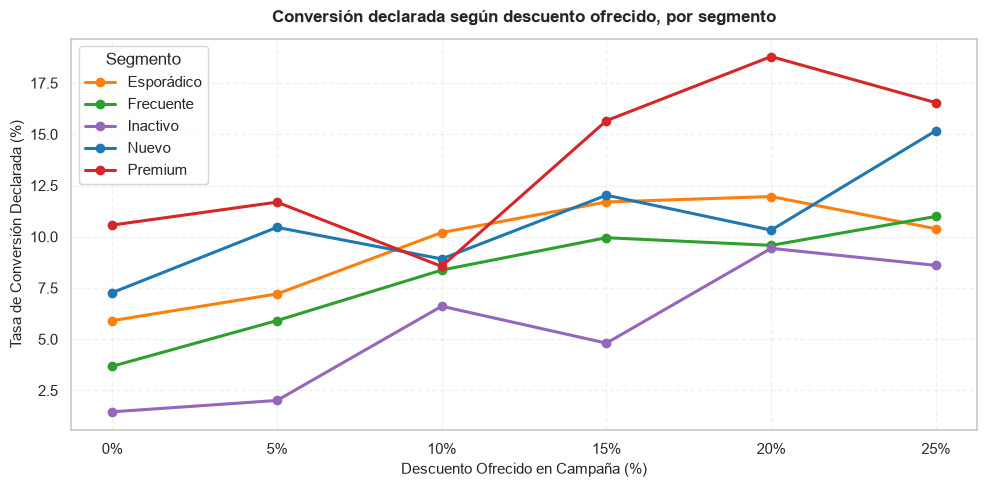

In [10]:
# Curvas de Conversión vs Descuento (Sin sombreados artificiales)
fig, ax = plt.subplots(figsize=(10, 5))

colores_seg = {
    'Premium': '#D62728',
    'Frecuente': '#2CA02C',
    'Esporádico': '#FF7F0E',
    'Nuevo': '#1F77B4',
    'Inactivo': '#9467BD'
}

descuentos_pct = [int(col * 100) for col in piv_decl.columns]

for seg in piv_decl.index:
    ax.plot(descuentos_pct, piv_decl.loc[seg], marker='o', lw=2.2, label=seg, color=colores_seg.get(seg, 'gray'))

ax.set_title('Conversión declarada según descuento ofrecido, por segmento', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Descuento Ofrecido en Campaña (%)', fontsize=11)
ax.set_ylabel('Tasa de Conversión Declarada (%)', fontsize=11)
ax.set_xticks(descuentos_pct)
ax.set_xticklabels([f"{d}%" for d in descuentos_pct])
ax.grid(alpha=0.3, linestyle='--')
ax.legend(title='Segmento', frameon=True)

plt.tight_layout()
plt.show()


---
## A4.3 No conversión y fricción operativa (C3)

**Pregunta:** ¿los clientes que nunca convirtieron estuvieron más expuestos a quejas en CRM o a devoluciones que los que sí convirtieron?

Se compara la proporción de clientes con cada indicador de fricción entre ambos grupos, con prueba de diferencia de proporciones (z y chi-cuadrado) e intervalo de confianza del 95%. Después se examinan hipótesis alternativas con datos: composición por segmento, nivel de descuento y confiabilidad del flag `convertido`. Las cifras y la conclusión se imprimen debajo de cada celda.

In [11]:
# 1. Fricción operativa vs. conversión: diferencia de proporciones con IC 95% (C3a)
from statsmodels.stats.proportion import proportions_ztest

camp_cli = campanas.groupby('cliente_id').agg(
    impactos_totales=('campana_id', 'count'),
    conversiones_totales=('convertido', 'sum'),
    conversiones_validadas=('convertido_validado_30d', 'sum'),
    descuento_medio_recibido=('descuento_ofrecido', 'mean')
).reset_index()

cli_mkt = clientes.merge(camp_cli, on='cliente_id', how='inner')
cli_mkt['convirtio_alguna_vez'] = cli_mkt['conversiones_totales'] > 0
cli_mkt['convirtio_validado'] = cli_mkt['conversiones_validadas'] > 0
cli_mkt['tiene_quejas'] = cli_mkt['n_quejas'] > 0
cli_mkt['tiene_quejas_no_resueltas'] = cli_mkt['n_quejas_sin_resolver'] > 0
cli_mkt['tiene_devoluciones'] = cli_mkt['n_devoluciones'] > 0

INDICADORES_FRICCION = {
    'tiene_quejas': 'Con quejas',
    'tiene_quejas_no_resueltas': 'Con quejas no resueltas',
    'tiene_devoluciones': 'Con devoluciones',
}


def comparar_friccion(df, col_grupo):
    """Para cada indicador: % en cada grupo, diferencia (sí − nunca), IC 95% (Wald), prueba z y chi-cuadrado."""
    filas = []
    no, si = df[~df[col_grupo]], df[df[col_grupo]]
    for col, nombre in INDICADORES_FRICCION.items():
        x = np.array([si[col].sum(), no[col].sum()])
        n = np.array([len(si), len(no)])
        p1, p0 = x / n
        dif = p1 - p0
        ee = np.sqrt(p1 * (1 - p1) / n[0] + p0 * (1 - p0) / n[1])
        z, p_z = proportions_ztest(x, n)
        chi2, p_chi, _, _ = stats.chi2_contingency(pd.crosstab(df[col_grupo], df[col]))
        filas.append({'Indicador': nombre, 'Nunca convirtieron (%)': p0 * 100, 'Sí convirtieron (%)': p1 * 100,
                      'Diferencia (p.p.)': dif * 100, 'IC 95% inf': (dif - 1.96 * ee) * 100,
                      'IC 95% sup': (dif + 1.96 * ee) * 100, 'z': z, 'p (z)': p_z, 'Chi2': chi2, 'p (chi2)': p_chi})
    return pd.DataFrame(filas)


friccion_test = comparar_friccion(cli_mkt, 'convirtio_alguna_vez')
friccion_resumen = cli_mkt.groupby('convirtio_alguna_vez').agg(
    n_clientes=('cliente_id', 'count'),
    tasa_con_quejas=('tiene_quejas', lambda s: s.mean() * 100),
    tasa_quejas_no_resueltas=('tiene_quejas_no_resueltas', lambda s: s.mean() * 100),
    tasa_con_devoluciones=('tiene_devoluciones', lambda s: s.mean() * 100),
).reset_index()
n_no_conv = int((~cli_mkt['convirtio_alguna_vez']).sum())
n_si_conv = int(cli_mkt['convirtio_alguna_vez'].sum())
p_q = friccion_test.loc[0, 'p (chi2)']
hay_diferencia_friccion = bool((friccion_test['p (z)'] < 0.05).any())

print(f"COMPARACIÓN DE FRICCIÓN OPERATIVA (conversión declarada): nunca convirtieron n = {n_no_conv:,} | "
      f"sí convirtieron n = {n_si_conv:,}")
display(friccion_test.round(4))

print("\nLectura (generada a partir de las pruebas):")
for _, r in friccion_test.iterrows():
    print(f"• {r['Indicador']}: {r['Nunca convirtieron (%)']:.2f}% vs {r['Sí convirtieron (%)']:.2f}%, diferencia "
          f"{r['Diferencia (p.p.)']:+.2f} p.p. (IC 95% [{r['IC 95% inf']:+.2f}, {r['IC 95% sup']:+.2f}]), p = {r['p (z)']:.3f} → "
          + ("diferencia significativa al 5%." if r['p (z)'] < 0.05 else "no hay diferencia significativa."))
if not hay_diferencia_friccion:
    print("• Ningún indicador de fricción difiere entre quienes convirtieron y quienes nunca convirtieron: los datos no "
          "asocian la no conversión con quejas ni devoluciones.")
    print("• Es coherente con A3, donde tampoco se detecta efecto de las quejas no resueltas sobre la frecuencia de compra.")

COMPARACIÓN DE FRICCIÓN OPERATIVA (conversión declarada): nunca convirtieron n = 4,062 | sí convirtieron n = 738


,Indicador,Nunca convirtieron (%),Sí convirtieron (%),Diferencia (p.p.),IC 95% inf,IC 95% sup,z,p (z),Chi2,p (chi2)
0,Con quejas,17.5037,17.7507,0.2470,-2.7473,3.2412,0.1623,0.8711,0.0120,0.9127
1,Con quejas no resueltas,5.7115,5.1491,-0.5624,-2.3093,1.1845,-0.6100,0.5418,0.2737,0.6008
2,Con devoluciones,44.9532,44.5799,-0.3733,-4.2721,3.5256,-0.1875,0.8512,0.0217,0.8829



Lectura (generada a partir de las pruebas):
• Con quejas: 17.50% vs 17.75%, diferencia +0.25 p.p. (IC 95% [-2.75, +3.24]), p = 0.871 → no hay diferencia significativa.
• Con quejas no resueltas: 5.71% vs 5.15%, diferencia -0.56 p.p. (IC 95% [-2.31, +1.18]), p = 0.542 → no hay diferencia significativa.
• Con devoluciones: 44.95% vs 44.58%, diferencia -0.37 p.p. (IC 95% [-4.27, +3.53]), p = 0.851 → no hay diferencia significativa.
• Ningún indicador de fricción difiere entre quienes convirtieron y quienes nunca convirtieron: los datos no asocian la no conversión con quejas ni devoluciones.
• Es coherente con A3, donde tampoco se detecta efecto de las quejas no resueltas sobre la frecuencia de compra.


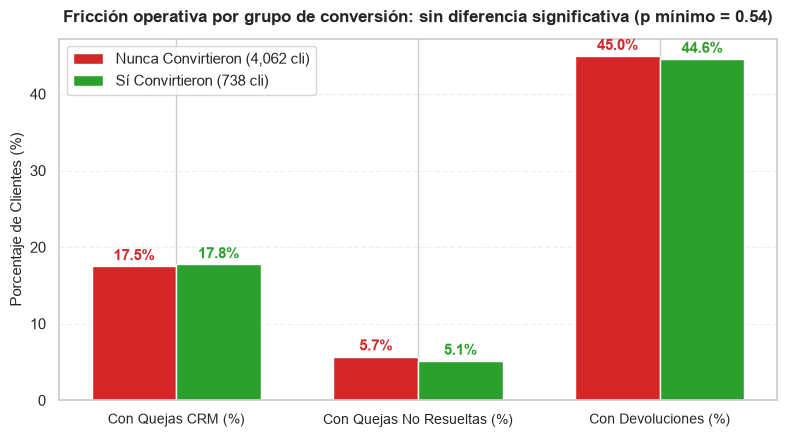

In [12]:
# Gráfica de Fricciones Operativas con Etiquetas Dinámicas (C17)
fig, ax = plt.subplots(figsize=(8, 4.5))

indicadores = ['Con Quejas CRM (%)', 'Con Quejas No Resueltas (%)', 'Con Devoluciones (%)']
valores_no_conv = [
    friccion_resumen.loc[0, 'tasa_con_quejas'],
    friccion_resumen.loc[0, 'tasa_quejas_no_resueltas'],
    friccion_resumen.loc[0, 'tasa_con_devoluciones']
]
valores_si_conv = [
    friccion_resumen.loc[1, 'tasa_con_quejas'],
    friccion_resumen.loc[1, 'tasa_quejas_no_resueltas'],
    friccion_resumen.loc[1, 'tasa_con_devoluciones']
]
n_no = friccion_resumen.loc[0, 'n_clientes']
n_si = friccion_resumen.loc[1, 'n_clientes']

x = np.arange(len(indicadores))
width = 0.35

ax.bar(x - width/2, valores_no_conv, width, label=f'Nunca Convirtieron ({n_no:,} cli)', color='#D62728')
ax.bar(x + width/2, valores_si_conv, width, label=f'Sí Convirtieron ({n_si:,} cli)', color='#2CA02C')

p_min_friccion = friccion_test['p (z)'].min()
ax.set_title('Fricción operativa por grupo de conversión: ' + ('sin diferencia significativa' if p_min_friccion >= 0.05 else 'hay diferencias significativas')
             + f' (p mínimo = {p_min_friccion:.2f})', fontsize=12, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(indicadores, fontsize=10)
ax.set_ylabel('Porcentaje de Clientes (%)', fontsize=11)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.legend(frameon=True)

for i in range(len(indicadores)):
    ax.annotate(f"{valores_no_conv[i]:.1f}%", (x[i] - width/2, valores_no_conv[i] + 0.8), ha='center', fontweight='bold', color='#D62728')
    ax.annotate(f"{valores_si_conv[i]:.1f}%", (x[i] + width/2, valores_si_conv[i] + 0.8), ha='center', fontweight='bold', color='#2CA02C')

plt.tight_layout()
plt.show()


In [13]:
# 2. Hipótesis alternativas para la no conversión, respaldadas por datos (C3d)
# H1: composición por segmento | H2: nivel de descuento | H3: confiabilidad del flag `convertido`
# Todas son asociaciones descriptivas, no efectos causales.

# --- H1. Composición por segmento
seg_cli = pd.crosstab(cli_mkt['segmento'], cli_mkt['convirtio_alguna_vez'], normalize='columns') * 100
seg_cli.columns = ['% entre nunca convirtieron', '% entre sí convirtieron']
chi2_seg, p_seg, _, _ = stats.chi2_contingency(pd.crosstab(cli_mkt['segmento'], cli_mkt['convirtio_alguna_vez']))
seg_env = campanas.groupby('segmento').agg(
    envios=('campana_id', 'count'),
    conv_declarada_pct=('convertido', lambda s: s.mean() * 100),
    compra_30d_pct=('compra_30d', lambda s: s.mean() * 100),
    conv_validada_pct=('convertido_validado_30d', lambda s: s.mean() * 100),
)
seg_env['pct_envios'] = seg_env['envios'] / seg_env['envios'].sum() * 100
print("--- H1. COMPOSICIÓN POR SEGMENTO ---")
display(seg_cli.round(2))
print(f"Segmento × conversión (clientes): Chi2 = {chi2_seg:.2f}, p = {p_seg:.4g}")
display(seg_env.round(2))
nuevo_inact = seg_env.loc[['Nuevo', 'Inactivo']]
print(f"• Nuevo e Inactivo reciben {nuevo_inact['pct_envios'].sum():.1f}% de los envíos. Declaran conversión de "
      f"{nuevo_inact.loc['Nuevo', 'conv_declarada_pct']:.2f}% y {nuevo_inact.loc['Inactivo', 'conv_declarada_pct']:.2f}%, "
      f"pero solo compran en 30 días el {nuevo_inact.loc['Nuevo', 'compra_30d_pct']:.2f}% y "
      f"{nuevo_inact.loc['Inactivo', 'compra_30d_pct']:.2f}% (validada: {nuevo_inact.loc['Nuevo', 'conv_validada_pct']:.2f}% y "
      f"{nuevo_inact.loc['Inactivo', 'conv_validada_pct']:.2f}%).")

# --- H2. Nivel de descuento
desc_env = campanas.groupby('descuento_ofrecido').agg(
    envios=('campana_id', 'count'),
    conv_declarada_pct=('convertido', lambda s: s.mean() * 100),
    conv_validada_pct=('convertido_validado_30d', lambda s: s.mean() * 100),
)
desc_no = cli_mkt.loc[~cli_mkt['convirtio_alguna_vez'], 'descuento_medio_recibido']
desc_si = cli_mkt.loc[cli_mkt['convirtio_alguna_vez'], 'descuento_medio_recibido']
t_desc, p_desc = stats.ttest_ind(desc_si, desc_no, equal_var=False)
print("\n--- H2. NIVEL DE DESCUENTO ---")
display(desc_env.round(2))
print(f"• Descuento medio recibido por cliente: nunca convirtieron {desc_no.mean()*100:.2f}% vs sí convirtieron "
      f"{desc_si.mean()*100:.2f}% (Welch t = {t_desc:.2f}, p = {p_desc:.4g}). La relación descuento-conversión se modela en A4.2.")

# --- H3. Confiabilidad del flag declarado: la fricción con la conversión validada
friccion_val = comparar_friccion(cli_mkt, 'convirtio_validado')
print("\n--- H3. CONFIABILIDAD DEL FLAG: FRICCIÓN SEGÚN CONVERSIÓN VALIDADA (compra real en 30 días) ---")
print(f"Clientes con alguna conversión validada: {int(cli_mkt['convirtio_validado'].sum()):,} de {len(cli_mkt):,}")
display(friccion_val.round(4))
print("• La calidad del flag `convertido` se audita en A4.1 (P(compra en 30 días | convertido)).")
compras_val = cli_mkt.groupby('convirtio_validado')['n_compras'].mean()
dev_por_compra = cli_mkt.groupby('convirtio_validado').apply(lambda d: d['n_devoluciones'].sum() / d['n_compras'].sum() * 100)
print(f"• Compras promedio por cliente: sin conversión validada {compras_val[False]:.2f} vs con conversión validada {compras_val[True]:.2f}; "
      f"devoluciones por cada 100 compras: {dev_por_compra[False]:.2f} vs {dev_por_compra[True]:.2f}.")
for _, r in friccion_val.iterrows():
    if r['p (z)'] < 0.05:
        print(f"• {r['Indicador']}: {r['Nunca convirtieron (%)']:.2f}% vs {r['Sí convirtieron (%)']:.2f}% (p = {r['p (z)']:.3g}). "
              + ("La diferencia va en dirección contraria a la hipótesis de fricción: es mayor entre quienes SÍ compraron, "
                 "que también compran más veces y por tanto tienen más oportunidades de devolver."
                 if r['Diferencia (p.p.)'] > 0 else "Es mayor entre quienes nunca convirtieron."))
if not (friccion_val['p (z)'] < 0.05).any():
    print("• Con la conversión validada tampoco hay diferencias significativas en fricción.")

--- H1. COMPOSICIÓN POR SEGMENTO ---


,% entre nunca convirtieron,% entre sí convirtieron
segmento,,
Esporádico,34.61,37.53
Frecuente,30.80,27.24
Inactivo,15.73,8.67
Nuevo,9.82,12.20
Premium,9.03,14.36


Segmento × conversión (clientes): Chi2 = 46.83, p = 1.654e-09


,envios,conv_declarada_pct,compra_30d_pct,conv_validada_pct,pct_envios
segmento,,,,,
Esporádico,3118,9.53,10.65,1.03,35.35
Frecuente,2654,8.03,34.33,2.86,30.09
Inactivo,1238,5.49,3.23,0.16,14.04
Nuevo,933,10.61,5.79,0.43,10.58
Premium,877,13.68,52.00,7.41,9.94


• Nuevo e Inactivo reciben 24.6% de los envíos. Declaran conversión de 10.61% y 5.49%, pero solo compran en 30 días el 5.79% y 3.23% (validada: 0.43% y 0.16%).

--- H2. NIVEL DE DESCUENTO ---


,envios,conv_declarada_pct,conv_validada_pct
descuento_ofrecido,,,
0.00,1481,5.13,1.49
0.05,1504,6.91,1.86
0.10,1456,8.79,1.51
0.15,1467,10.70,2.11
0.20,1454,11.42,2.34
0.25,1458,11.39,2.88


• Descuento medio recibido por cliente: nunca convirtieron 12.16% vs sí convirtieron 13.62% (Welch t = 5.77, p = 1.014e-08). La relación descuento-conversión se modela en A4.2.

--- H3. CONFIABILIDAD DEL FLAG: FRICCIÓN SEGÚN CONVERSIÓN VALIDADA (compra real en 30 días) ---
Clientes con alguna conversión validada: 167 de 4,800


,Indicador,Nunca convirtieron (%),Sí convirtieron (%),Diferencia (p.p.),IC 95% inf,IC 95% sup,z,p (z),Chi2,p (chi2)
0,Con quejas,17.5912,16.1677,-1.4235,-7.1139,4.2669,-0.4752,0.6346,0.1381,0.7101
1,Con quejas no resueltas,5.6767,4.1916,-1.4851,-4.5966,1.6265,-0.8183,0.4132,0.4191,0.5174
2,Con devoluciones,44.0104,69.4611,25.4507,18.3205,32.5809,6.4964,0.0000,41.1809,0.0000


• La calidad del flag `convertido` se audita en A4.1 (P(compra en 30 días | convertido)).
• Compras promedio por cliente: sin conversión validada 5.96 vs con conversión validada 11.65; devoluciones por cada 100 compras: 13.41 vs 12.44.
• Con devoluciones: 44.01% vs 69.46% (p = 8.23e-11). La diferencia va en dirección contraria a la hipótesis de fricción: es mayor entre quienes SÍ compraron, que también compran más veces y por tanto tienen más oportunidades de devolver.


---
## A4.4 Atribución Last-Touch a 30 Días: Retorno Bruto (no incremental) vs. ROI Incremental

### 1. Retorno bruto (no incremental): una identidad contable
La contabilidad publicitaria tradicional atribuye a la campaña toda compra ocurrida en los 30 días posteriores al envío. Si el costo se define como el descuento implícito:
$$\text{Costo} = d \times \text{Monto Atribuido}$$

entonces:
$$\text{Retorno Bruto de Ingreso} = \frac{\text{Monto Atribuido}}{\text{Costo}} = \frac{1}{\bar d}
\qquad
\text{Retorno Bruto de Margen} = \frac{\text{Margen Atribuido}}{\text{Costo}} = \frac{\bar m}{\bar d}$$

donde $\bar d$ es el descuento medio ponderado por monto y $\bar m$ el margen porcentual atribuido.

**Advertencia:** este indicador es una **identidad matemática, no una medida de efectividad**. Las diferencias entre tipos de campaña reflejan su descuento medio, y el indicador no dice si la campaña indujo alguna compra adicional. La celda siguiente verifica la identidad con los datos y compara el ritmo de compras atribuidas con el ritmo base de compra.

### 2. Efecto incremental
Para estimar si las campañas generan compras adicionales se compara, para el **mismo cliente**, la tasa de compra en los 30 días posteriores a cada envío con su tasa de compra en ventanas de igual duración **sin ninguna campaña** en los 30 días previos. El intervalo de confianza se obtiene por bootstrap remuestreando clientes. Con ese lift se calcula el **ROI incremental** = (margen incremental − costo del descuento) / costo del descuento.

In [14]:
# 1. Atribución Last-Touch Estricta a 30 Días (Corrección C2: sin duplicados)
# Excluyendo diciembre 2024 por ventana incompleta de maduración
camp_elegible = campanas[campanas['fecha_envio'] < '2024-12-01'].copy()
VENTANA_ATRIB = pd.Timedelta(days=30)

# --- Método anterior (para comparar): cada campaña busca sus compras de forma independiente
# en [fecha_envio, fecha_envio + 30 días], por lo que una compra puede contarse en varias campañas.
pares = transacciones[['transaccion_id', 'cliente_id', 'fecha', 'monto_neto', 'margen_bruto']].merge(
    camp_elegible[['campana_id', 'cliente_id', 'fecha_envio', 'descuento_ofrecido']], on='cliente_id'
)
pares = pares[(pares['fecha'] >= pares['fecha_envio']) & (pares['fecha'] <= pares['fecha_envio'] + VENTANA_ATRIB)]
n_asignaciones_prev = len(pares)
monto_duplicado_prev = pares['monto_neto'].sum()
costo_duplicado_prev = (pares['descuento_ofrecido'] * pares['monto_neto']).sum()
campanas_por_tx = pares.groupby('transaccion_id')['campana_id'].count()
n_tx_multi_campana = int((campanas_por_tx > 1).sum())

# --- Atribución Last-Touch estricta: merge_asof asigna cada transacción exclusivamente
# a la campaña más reciente del cliente enviada en los 30 días previos a la compra
tx_sorted = transacciones.sort_values('fecha').copy()
camp_sorted = camp_elegible.sort_values('fecha_envio').copy()
merged_lt = pd.merge_asof(
    tx_sorted,
    camp_sorted[['campana_id', 'cliente_id', 'tipo_campana', 'canal_campana', 'descuento_ofrecido', 'fecha_envio']],
    by='cliente_id',
    left_on='fecha',
    right_on='fecha_envio',
    direction='backward',
    tolerance=VENTANA_ATRIB
)

tx_last_touch = merged_lt[merged_lt['campana_id'].notna()].copy()
tx_last_touch['costo_estimado'] = tx_last_touch['descuento_ofrecido'] * tx_last_touch['monto_neto']

# Control: las transacciones atribuidas son las mismas en ambos métodos; solo cambia cuántas veces se cuentan
assert set(tx_last_touch['transaccion_id']) == set(pares['transaccion_id'])

# Métricas consolidadas Last-Touch deduplicadas
n_tx_unicas = len(tx_last_touch)
monto_atribuido_lt = tx_last_touch['monto_neto'].sum()
margen_atribuido_lt = tx_last_touch['margen_bruto'].sum()
costo_estimado_lt = tx_last_touch['costo_estimado'].sum()
tx_eliminadas = n_asignaciones_prev - n_tx_unicas
delta_monto_c2 = monto_atribuido_lt - monto_duplicado_prev
delta_costo_c2 = costo_estimado_lt - costo_duplicado_prev

print("--- AUDITORÍA DE DEDUPLICACIÓN LAST-TOUCH (C2) ---")
print(f"• Método anterior: {n_asignaciones_prev:,} asignaciones compra-campaña sobre {campanas_por_tx.size:,} transacciones distintas")
print(f"• Transacciones atribuidas a más de una campaña en el método anterior: {n_tx_multi_campana:,}")
print("  Distribución de campañas por transacción (método anterior):")
print(campanas_por_tx.value_counts().sort_index().rename_axis('campañas').rename('transacciones').to_string())
print(f"• Last-touch: {n_tx_unicas:,} transacciones, cada una en una sola campaña ({tx_eliminadas:,} asignaciones duplicadas eliminadas)")
print(f"• Monto atribuido: ${monto_duplicado_prev:,.2f} → ${monto_atribuido_lt:,.2f} (variación de ${delta_monto_c2:,.2f})")
print(f"• Margen bruto atribuido (last-touch): ${margen_atribuido_lt:,.2f}")
print(f"• Costo en descuentos: ${costo_duplicado_prev:,.2f} → ${costo_estimado_lt:,.2f} (variación de ${delta_costo_c2:,.2f})")

# Tabla de Retorno Bruto por Tipo de Campaña
roi_tipo = tx_last_touch.groupby('tipo_campana').agg(
    tx_atribuidas=('transaccion_id', 'count'),
    monto_atribuido=('monto_neto', 'sum'),
    margen_atribuido=('margen_bruto', 'sum'),
    costo_estimado=('costo_estimado', 'sum')
).reset_index()

n_camps = camp_elegible.groupby('tipo_campana')['campana_id'].count().rename('campanas')
roi_tipo = roi_tipo.merge(n_camps, on='tipo_campana')

roi_tipo['retorno_bruto_ingreso'] = (roi_tipo['monto_atribuido'] / roi_tipo['costo_estimado']).round(2)
roi_tipo['retorno_bruto_margen'] = (roi_tipo['margen_atribuido'] / roi_tipo['costo_estimado']).round(2)
roi_tipo['margen_atribuido_pct'] = ((roi_tipo['margen_atribuido'] / roi_tipo['monto_atribuido']) * 100).round(2)
roi_tipo = roi_tipo.sort_values('retorno_bruto_margen', ascending=False)

print("\nRETORNO BRUTO (NO INCREMENTAL) POR TIPO DE CAMPAÑA, ATRIBUCIÓN LAST-TOUCH:")
display(roi_tipo[['tipo_campana', 'campanas', 'tx_atribuidas', 'monto_atribuido', 'costo_estimado',
                  'retorno_bruto_ingreso', 'retorno_bruto_margen', 'margen_atribuido_pct']].round(2))

--- AUDITORÍA DE DEDUPLICACIÓN LAST-TOUCH (C2) ---
• Método anterior: 2,176 asignaciones compra-campaña sobre 2,122 transacciones distintas
• Transacciones atribuidas a más de una campaña en el método anterior: 54
  Distribución de campañas por transacción (método anterior):
campañas
1    2068
2      54
• Last-touch: 2,122 transacciones, cada una en una sola campaña (54 asignaciones duplicadas eliminadas)
• Monto atribuido: $733,832.74 → $716,645.40 (variación de $-17,187.34)
• Margen bruto atribuido (last-touch): $179,403.17
• Costo en descuentos: $92,794.78 → $90,682.05 (variación de $-2,112.73)

RETORNO BRUTO (NO INCREMENTAL) POR TIPO DE CAMPAÑA, ATRIBUCIÓN LAST-TOUCH:


,tipo_campana,campanas,tx_atribuidas,monto_atribuido,costo_estimado,retorno_bruto_ingreso,retorno_bruto_margen,margen_atribuido_pct
2,push_reactivacion,1678,436,145872.19,17956.34,8.12,2.06,25.32
0,email_descuento,2965,738,248505.11,31345.45,7.93,1.99,25.11
3,sms_oferta_flash,1291,323,116610.90,14830.59,7.86,1.97,25.10
1,email_fidelizacion,1691,430,137478.00,17159.16,8.01,1.93,24.08
4,social_ads,825,195,68179.20,9390.51,7.26,1.88,25.95


In [15]:
# Verificación de la identidad contable del retorno bruto (C1a)
# Con costo = descuento × monto, el retorno de ingreso es 1 / (descuento medio ponderado por monto)
# y el retorno de margen es (margen % atribuido) / (descuento medio ponderado). No mide efectividad.
d_medio_global = costo_estimado_lt / monto_atribuido_lt
m_medio_global = margen_atribuido_lt / monto_atribuido_lt

print("--- IDENTIDAD DEL RETORNO BRUTO (C1a) ---")
print(f"• Descuento medio ponderado por monto atribuido: {d_medio_global*100:.3f}%")
print(f"• Retorno bruto de ingreso = monto / costo = {monto_atribuido_lt / costo_estimado_lt:.4f} "
      f"| 1 / descuento medio = {1 / d_medio_global:.4f}")
print(f"• Retorno bruto de margen = margen / costo = {margen_atribuido_lt / costo_estimado_lt:.4f} "
      f"| margen % / descuento medio = {m_medio_global / d_medio_global:.4f}")

identidad_tipo = roi_tipo[['tipo_campana', 'retorno_bruto_ingreso', 'retorno_bruto_margen']].copy()
identidad_tipo['descuento_medio_pct'] = (roi_tipo['costo_estimado'] / roi_tipo['monto_atribuido'] * 100).round(3)
identidad_tipo['1/descuento_medio'] = (roi_tipo['monto_atribuido'] / roi_tipo['costo_estimado']).round(2)
identidad_tipo['margen%/descuento%'] = (roi_tipo['margen_atribuido'] / roi_tipo['costo_estimado']).round(2)
print("\nPor tipo, el retorno bruto coincide con 1/descuento medio y con margen%/descuento% del propio tipo:")
display(identidad_tipo)

# Ritmo de compras atribuidas por envío vs. ritmo base de cualquier cliente
meses_serie = transacciones['fecha'].dt.to_period('M').nunique()
ritmo_base = len(transacciones) / (len(clientes) * meses_serie)
compras_por_envio = n_tx_unicas / len(camp_elegible)
print(f"\n• Compras atribuidas por envío en 30 días: {n_tx_unicas:,} / {len(camp_elegible):,} = {compras_por_envio:.4f}")
print(f"• Ritmo base de compra por cliente-mes: {len(transacciones):,} / ({len(clientes):,} × {meses_serie}) = {ritmo_base:.4f}")
print("  El retorno bruto cuenta como efecto de la campaña compras que, a ese ritmo, ocurrirían igual sin ella.")
print("  Por eso las diferencias entre tipos reflejan su descuento medio, no su efectividad. El efecto incremental se estima abajo.")

--- IDENTIDAD DEL RETORNO BRUTO (C1a) ---
• Descuento medio ponderado por monto atribuido: 12.654%
• Retorno bruto de ingreso = monto / costo = 7.9028 | 1 / descuento medio = 7.9028
• Retorno bruto de margen = margen / costo = 1.9784 | margen % / descuento medio = 1.9784

Por tipo, el retorno bruto coincide con 1/descuento medio y con margen%/descuento% del propio tipo:


,tipo_campana,retorno_bruto_ingreso,retorno_bruto_margen,descuento_medio_pct,1/descuento_medio,margen%/descuento%
2,push_reactivacion,8.12,2.06,12.310,8.12,2.06
0,email_descuento,7.93,1.99,12.614,7.93,1.99
3,sms_oferta_flash,7.86,1.97,12.718,7.86,1.97
1,email_fidelizacion,8.01,1.93,12.481,8.01,1.93
4,social_ads,7.26,1.88,13.773,7.26,1.88



• Compras atribuidas por envío en 30 días: 2,122 / 8,450 = 0.2511
• Ritmo base de compra por cliente-mes: 50,000 / (8,000 × 24) = 0.2604
  El retorno bruto cuenta como efecto de la campaña compras que, a ese ritmo, ocurrirían igual sin ella.
  Por eso las diferencias entre tipos reflejan su descuento medio, no su efectividad. El efecto incremental se estima abajo.


In [16]:
# 2. Efecto incremental (C1b, C1c): tasa post-envío vs. referencia sin campaña del MISMO cliente
# - Tasa post: el cliente compró (cualquier compra) entre el día del envío y 30 días después.
# - Referencia: bloques de 31 días (mismo largo que la ventana post) del mismo cliente, sin ninguna
#   campaña enviada durante el bloque ni en los 30 días previos. Solo bloques posteriores al alta del
#   cliente; se descarta el primer bloque porque no se conocen campañas anteriores al inicio de la serie.
# - Lift = tasa post − tasa de referencia del mismo cliente, promediado sobre envíos.
# - IC 95% por bootstrap remuestreando CLIENTES (seed 42).
SEED = 42
N_BOOT = 2000
LARGO_VENTANA = VENTANA_ATRIB.days + 1          # día del envío + 30 días = 31 días
INICIO_SERIE = transacciones['fecha'].min()
FIN_SERIE = transacciones['fecha'].max()

# --- Tasa post por envío (cualquier compra del cliente en la ventana)
p = camp_elegible[['campana_id', 'cliente_id', 'fecha_envio']].merge(
    transacciones[['cliente_id', 'fecha']], on='cliente_id')
p = p[(p['fecha'] >= p['fecha_envio']) & (p['fecha'] <= p['fecha_envio'] + VENTANA_ATRIB)]
camp_elegible['compro_post'] = camp_elegible['campana_id'].isin(p['campana_id']).astype(int)

# --- Bloques de referencia por cliente
n_bloques = (FIN_SERIE - INICIO_SERIE).days // LARGO_VENTANA
bloques = pd.DataFrame({'bloque': range(1, n_bloques)})     # se descarta el bloque 0
bloques['ini'] = INICIO_SERIE + pd.to_timedelta(bloques['bloque'] * LARGO_VENTANA, unit='D')
bloques['fin'] = bloques['ini'] + pd.Timedelta(days=LARGO_VENTANA - 1)

alta = clientes[['cliente_id']].assign(alta=pd.to_datetime(clientes['fecha_alta_efectiva']))
cli_bloq = alta.merge(bloques, how='cross')
cli_bloq = cli_bloq[cli_bloq['ini'] >= cli_bloq['alta']]

# Bloques "contaminados": alguna campaña (de cualquier mes, incluido dic-2024) en [ini - 30 días, fin]
cb = campanas[['cliente_id', 'fecha_envio']].merge(bloques, how='cross')
cb = cb[(cb['fecha_envio'] >= cb['ini'] - VENTANA_ATRIB) & (cb['fecha_envio'] <= cb['fin'])]
contaminados = set(zip(cb['cliente_id'], cb['bloque']))
cli_bloq = cli_bloq[[k not in contaminados for k in zip(cli_bloq['cliente_id'], cli_bloq['bloque'])]]

bloque_tx = (transacciones['fecha'] - INICIO_SERIE).dt.days // LARGO_VENTANA
con_compra = set(zip(transacciones['cliente_id'], bloque_tx))
cli_bloq['compro'] = [int(k in con_compra) for k in zip(cli_bloq['cliente_id'], cli_bloq['bloque'])]

ref_cli = cli_bloq.groupby('cliente_id').agg(bloques_ref=('compro', 'size'), bloques_con_compra=('compro', 'sum'))
ref_cli['tasa_ref'] = ref_cli['bloques_con_compra'] / ref_cli['bloques_ref']

camp_elegible = camp_elegible.drop(columns=['tasa_ref'], errors='ignore').merge(
    ref_cli[['tasa_ref']], left_on='cliente_id', right_index=True, how='left')
con_ref = camp_elegible['tasa_ref'].notna()

print("--- EFECTO INCREMENTAL: TASA POST-ENVÍO vs. REFERENCIA SIN CAMPAÑA DEL MISMO CLIENTE (C1) ---")
print(f"• Envíos elegibles: {len(camp_elegible):,} | con referencia del mismo cliente: {con_ref.sum():,} "
      f"({camp_elegible.loc[con_ref, 'cliente_id'].nunique():,} clientes)")
print(f"• Envíos sin referencia (el cliente nunca tuvo un bloque de {LARGO_VENTANA} días sin campaña): {(~con_ref).sum():,}")
print(f"• Bloques de referencia usados: {len(cli_bloq):,} (tasa de compra en bloques sin campaña: {cli_bloq['compro'].mean()*100:.2f}%)")

# --- Agregados por cliente (y por tipo) para el bootstrap
cli_ids = camp_elegible['cliente_id'].unique()
pos = pd.Series(np.arange(len(cli_ids)), index=cli_ids)
rng = np.random.default_rng(SEED)
W = rng.multinomial(len(cli_ids), np.full(len(cli_ids), 1 / len(cli_ids)), size=N_BOOT)   # pesos bootstrap


def por_cliente(serie):
    """Suma por cliente alineada con cli_ids (0 si el cliente no aparece)."""
    return serie.groupby(level=0).sum().reindex(cli_ids, fill_value=0).to_numpy(dtype=float)


def efecto(envios, tx_attr):
    """Lift, ROI incremental e IC bootstrap para un subconjunto de envíos y sus compras last-touch."""
    e = envios.set_index('cliente_id')
    er = e[e['tasa_ref'].notna()]
    S = por_cliente(er['compro_post'] - er['tasa_ref'])            # Σ (post − ref) por cliente
    N_ref = por_cliente(er['compro_post'] * 0 + 1)                  # envíos con referencia
    POST = por_cliente(er['compro_post'])
    N_env = por_cliente(e['compro_post'] * 0 + 1)                   # todos los envíos
    t = tx_attr.set_index('cliente_id')
    MARG, NTX, COSTO = por_cliente(t['margen_bruto']), por_cliente(t['monto_neto'] * 0 + 1), por_cliente(t['costo_estimado'])

    def calc(w):
        lift = (w @ S) / (w @ N_ref)
        margen_inc = lift * (w @ N_env) * (w @ MARG) / (w @ NTX)
        costo = w @ COSTO
        return lift, margen_inc, (margen_inc - costo) / costo

    uno = np.ones(len(cli_ids))
    lift, margen_inc, roi = calc(uno)
    b_lift, b_marg, b_roi = calc(W)
    return {
        'envios': int(uno @ N_env), 'envios_con_ref': int(uno @ N_ref),
        'tasa_post': (uno @ POST) / (uno @ N_ref) * 100, 'tasa_ref': (uno @ POST - uno @ S) / (uno @ N_ref) * 100,
        'lift_pp': lift * 100, 'ic_lift': np.percentile(b_lift * 100, [2.5, 97.5]),
        'p_lift': min(1.0, 2 * min((b_lift <= 0).mean(), (b_lift >= 0).mean())),
        'margen_prom': (uno @ MARG) / (uno @ NTX), 'costo': uno @ COSTO,
        'margen_inc': margen_inc, 'ic_margen_inc': np.percentile(b_marg, [2.5, 97.5]),
        'roi_inc': roi, 'ic_roi': np.percentile(b_roi, [2.5, 97.5]),
    }


ef_global = efecto(camp_elegible, tx_last_touch)
filas = []
for tipo, g in camp_elegible.groupby('tipo_campana'):
    r = efecto(g, tx_last_touch[tx_last_touch['tipo_campana'] == tipo])
    filas.append({'tipo_campana': tipo, **r})
filas.append({'tipo_campana': 'TOTAL', **ef_global})
df_lift_tipo = pd.DataFrame(filas)

tasa_post_base, tasa_pre_base = ef_global['tasa_post'], ef_global['tasa_ref']
lift_global_pp, ic_lift_global, p_lift_global = ef_global['lift_pp'], ef_global['ic_lift'], ef_global['p_lift']
margen_incremental, ic_margen_inc = ef_global['margen_inc'], ef_global['ic_margen_inc']
roi_incremental_global, ic_roi_global = ef_global['roi_inc'], ef_global['ic_roi']
costo_unico, margen_prom_compra = ef_global['costo'], ef_global['margen_prom']

tabla = df_lift_tipo.assign(
    **{'IC 95% lift (p.p.)': df_lift_tipo['ic_lift'].map(lambda x: f"[{x[0]:+.2f}, {x[1]:+.2f}]"),
       'IC 95% ROI incr.': df_lift_tipo['ic_roi'].map(lambda x: f"[{x[0]:.2f}, {x[1]:.2f}]")}
)[['tipo_campana', 'envios', 'envios_con_ref', 'tasa_post', 'tasa_ref', 'lift_pp', 'IC 95% lift (p.p.)', 'p_lift',
   'margen_inc', 'costo', 'roi_inc', 'IC 95% ROI incr.']]
print(f"\nLIFT Y ROI INCREMENTAL POR TIPO (bootstrap por cliente, {N_BOOT:,} réplicas, seed {SEED}):")
display(tabla.round(3))

print("\n--- LECTURA DEL RESULTADO (texto generado a partir de las cifras) ---")
for _, r in df_lift_tipo.iterrows():
    incluye0 = r['ic_lift'][0] <= 0 <= r['ic_lift'][1]
    print(f"• {r['tipo_campana']}: lift {r['lift_pp']:+.2f} p.p., IC 95% [{r['ic_lift'][0]:+.2f}, {r['ic_lift'][1]:+.2f}] → "
          + ("el intervalo INCLUYE 0: no se detecta efecto incremental." if incluye0
             else ("el intervalo no incluye 0: tasa post mayor que la referencia." if r['lift_pp'] > 0
                   else "el intervalo no incluye 0: tasa post MENOR que la referencia.")))
inc0_roi = ic_roi_global[0] <= 0 <= ic_roi_global[1]
print(f"• ROI incremental global = (margen incremental − costo) / costo = "
      f"(${margen_incremental:,.2f} − ${costo_unico:,.2f}) / ${costo_unico:,.2f} = {roi_incremental_global:.2f}")
print(f"  Margen incremental = lift × envíos × margen promedio por compra = "
      f"{lift_global_pp/100:+.4f} × {ef_global['envios']:,} × ${margen_prom_compra:.2f}")
print(f"  IC 95% del ROI incremental: [{ic_roi_global[0]:.2f}, {ic_roi_global[1]:.2f}] → "
      + ("INCLUYE 0." if inc0_roi else
         ("no incluye 0: el margen incremental estimado no cubre el costo del descuento." if ic_roi_global[1] < 0
          else "no incluye 0: el margen incremental estimado supera el costo del descuento.")))
inc_menos1 = ic_roi_global[0] <= -1 <= ic_roi_global[1]
print("  Un ROI incremental de −1 equivale a margen incremental cero (se paga el descuento sin ventas adicionales). "
      + ("El intervalo INCLUYE −1." if inc_menos1 else "El intervalo no incluye −1."))

--- EFECTO INCREMENTAL: TASA POST-ENVÍO vs. REFERENCIA SIN CAMPAÑA DEL MISMO CLIENTE (C1) ---
• Envíos elegibles: 8,450 | con referencia del mismo cliente: 8,363 (4,651 clientes)
• Envíos sin referencia (el cliente nunca tuvo un bloque de 31 días sin campaña): 87
• Bloques de referencia usados: 131,229 (tasa de compra en bloques sin campaña: 23.18%)



LIFT Y ROI INCREMENTAL POR TIPO (bootstrap por cliente, 2,000 réplicas, seed 42):


,tipo_campana,envios,envios_con_ref,tasa_post,tasa_ref,lift_pp,IC 95% lift (p.p.),p_lift,margen_inc,costo,roi_inc,IC 95% ROI incr.
0,email_descuento,2965,2931,20.368,21.401,-1.033,"[-2.46, +0.38]",0.144,-2589.241,31345.448,-1.083,"[-1.21, -0.97]"
1,email_fidelizacion,1691,1679,21.024,20.886,0.139,"[-1.72, +1.98]",0.856,180.633,17159.160,-0.989,"[-1.14, -0.85]"
2,push_reactivacion,1678,1661,21.312,21.329,-0.016,"[-1.99, +1.95]",0.949,-22.895,17956.345,-1.001,"[-1.17, -0.86]"
3,sms_oferta_flash,1291,1282,20.983,20.746,0.236,"[-1.87, +2.38]",0.829,276.578,14830.588,-0.981,"[-1.16, -0.82]"
4,social_ads,825,810,21.111,21.301,-0.190,"[-2.98, +2.45]",0.917,-142.050,9390.510,-1.015,"[-1.27, -0.81]"
5,TOTAL,8450,8363,20.854,21.173,-0.319,"[-1.25, +0.59]",0.463,-2282.236,90682.052,-1.025,"[-1.10, -0.95]"



--- LECTURA DEL RESULTADO (texto generado a partir de las cifras) ---
• email_descuento: lift -1.03 p.p., IC 95% [-2.46, +0.38] → el intervalo INCLUYE 0: no se detecta efecto incremental.
• email_fidelizacion: lift +0.14 p.p., IC 95% [-1.72, +1.98] → el intervalo INCLUYE 0: no se detecta efecto incremental.
• push_reactivacion: lift -0.02 p.p., IC 95% [-1.99, +1.95] → el intervalo INCLUYE 0: no se detecta efecto incremental.
• sms_oferta_flash: lift +0.24 p.p., IC 95% [-1.87, +2.38] → el intervalo INCLUYE 0: no se detecta efecto incremental.
• social_ads: lift -0.19 p.p., IC 95% [-2.98, +2.45] → el intervalo INCLUYE 0: no se detecta efecto incremental.
• TOTAL: lift -0.32 p.p., IC 95% [-1.25, +0.59] → el intervalo INCLUYE 0: no se detecta efecto incremental.
• ROI incremental global = (margen incremental − costo) / costo = ($-2,282.24 − $90,682.05) / $90,682.05 = -1.03
  Margen incremental = lift × envíos × margen promedio por compra = -0.0032 × 8,450 × $84.54
  IC 95% del ROI increme

In [17]:
# 3. Comparación complementaria antes/después del envío (sensibilidad del lift)
# Pre: compra en los 31 días anteriores al envío; post: compra entre el día del envío y 30 días después
# (ambas ventanas de 31 días). Esta comparación NO excluye campañas previas en la ventana pre,
# por eso es solo un complemento de la referencia sin campaña de la celda anterior.
q = camp_elegible[['campana_id', 'cliente_id', 'fecha_envio']].merge(
    transacciones[['cliente_id', 'fecha']], on='cliente_id')
q = q[(q['fecha'] < q['fecha_envio']) & (q['fecha'] >= q['fecha_envio'] - pd.Timedelta(days=LARGO_VENTANA))]
camp_elegible['compro_pre'] = camp_elegible['campana_id'].isin(q['campana_id']).astype(int)

audit = camp_elegible.sort_values(['cliente_id', 'fecha_envio']).copy()
audit['pre_truncada'] = audit['fecha_envio'] - pd.Timedelta(days=LARGO_VENTANA) < INICIO_SERIE
audit['dias_desde_envio_previo'] = audit.groupby('cliente_id')['fecha_envio'].diff().dt.days
audit['traslape_30d'] = audit['dias_desde_envio_previo'] <= VENTANA_ATRIB.days

subgrupos = {
    'Todas las campañas elegibles': audit,
    'Sin ventana pre truncada': audit[~audit['pre_truncada']],
    'Sin otra campaña en los 30 días previos': audit[~audit['traslape_30d']],
    'Sin truncar y sin traslape': audit[~audit['pre_truncada'] & ~audit['traslape_30d']],
    'Solo con ventana pre truncada': audit[audit['pre_truncada']],
}
filas_pp = []
for nombre, d in subgrupos.items():
    filas_pp.append({'subgrupo': nombre, 'envios': len(d),
                     'tasa_pre_%': d['compro_pre'].mean() * 100, 'tasa_post_%': d['compro_post'].mean() * 100,
                     'diferencia_pp': (d['compro_post'].mean() - d['compro_pre'].mean()) * 100})
df_pre_post = pd.DataFrame(filas_pp)
print("--- COMPARACIÓN COMPLEMENTARIA ANTES/DESPUÉS (ventanas de 31 días) ---")
display(df_pre_post.round(2))

limpias = df_pre_post.set_index('subgrupo').loc['Sin truncar y sin traslape']
truncadas = df_pre_post.set_index('subgrupo').loc['Solo con ventana pre truncada']
print(f"• En los {int(truncadas['envios']):,} envíos cuya ventana pre empieza antes del inicio de la serie, la tasa pre "
      f"es artificialmente baja ({truncadas['tasa_pre_%']:.2f}%), lo que infla su diferencia ({truncadas['diferencia_pp']:+.2f} p.p.).")
print(f"• En los {int(limpias['envios']):,} envíos sin truncar y sin traslape, la diferencia post − pre es "
      f"{limpias['diferencia_pp']:+.2f} p.p.; el lift contra la referencia sin campaña del mismo cliente es "
      f"{lift_global_pp:+.2f} p.p. (IC 95% [{ic_lift_global[0]:+.2f}, {ic_lift_global[1]:+.2f}]).")

--- COMPARACIÓN COMPLEMENTARIA ANTES/DESPUÉS (ventanas de 31 días) ---


,subgrupo,envios,tasa_pre_%,tasa_post_%,diferencia_pp
0,Todas las campañas elegibles,8450,20.90,20.66,-0.24
1,Sin ventana pre truncada,8063,21.39,20.80,-0.60
2,Sin otra campaña en los 30 días previos,8044,20.84,20.66,-0.17
3,Sin truncar y sin traslape,7663,21.34,20.80,-0.54
4,Solo con ventana pre truncada,387,10.59,17.83,7.24


• En los 387 envíos cuya ventana pre empieza antes del inicio de la serie, la tasa pre es artificialmente baja (10.59%), lo que infla su diferencia (+7.24 p.p.).
• En los 7,663 envíos sin truncar y sin traslape, la diferencia post − pre es -0.54 p.p.; el lift contra la referencia sin campaña del mismo cliente es -0.32 p.p. (IC 95% [-1.25, +0.59]).


In [18]:
# 4. Prueba Contrafactual: Comparación Contemporánea en el Mismo Período Calendario (R4)
contacted_ids = set(campanas['cliente_id'].unique())
never_contacted = clientes[~clientes['cliente_id'].isin(contacted_ids)].copy()
ctrl_by_seg = {seg: g['cliente_id'].values for seg, g in never_contacted.groupby('segmento')}

# Pareamiento contemporáneo por segmento en las mismas fechas
np.random.seed(42)
camp_elegible['ctrl_cli'] = [np.random.choice(ctrl_by_seg[s]) for s in camp_elegible['segmento']]

treated_bought, ctrl_bought = [], []
for _, r in camp_elegible.iterrows():
    f0 = np.datetime64(r['fecha_envio'])
    f1 = np.datetime64(r['fecha_envio'] + pd.Timedelta(days=30))
    
    t_tx = tx_por_cliente_fechas.get(r['cliente_id'])
    tb = np.any((t_tx >= f0) & (t_tx <= f1)) if t_tx is not None else False
    treated_bought.append(tb)
    
    c_tx = tx_por_cliente_fechas.get(r['ctrl_cli'])
    cb = np.any((c_tx >= f0) & (c_tx <= f1)) if c_tx is not None else False
    ctrl_bought.append(cb)

camp_elegible['treated_bought'] = treated_bought
camp_elegible['ctrl_bought'] = ctrl_bought
camp_elegible['diff_bought'] = camp_elegible['treated_bought'].astype(int) - camp_elegible['ctrl_bought'].astype(int)

tasa_contactados = camp_elegible['treated_bought'].mean() * 100
tasa_controles = camp_elegible['ctrl_bought'].mean() * 100
lift_calendario = tasa_contactados - tasa_controles

# Bootstrap del lift calendario por cliente
cli_ctrl_agg = camp_elegible.groupby('cliente_id').agg(
    n=('campana_id', 'count'),
    diff_sum=('diff_bought', 'sum')
)

b_lifts_cal = []
for _ in range(N_BOOT):
    idx = np.random.choice(cli_ctrl_agg.index, size=len(cli_ctrl_agg), replace=True)
    samp = cli_ctrl_agg.loc[idx]
    b_lifts_cal.append(samp['diff_sum'].sum() / samp['n'].sum() * 100)

ic_lift_cal = np.percentile(b_lifts_cal, [2.5, 97.5])

print("--- COMPARACIÓN EN EL MISMO PERÍODO CALENDARIO (R4) ---")
print(f"• Tasa Contactados (30d post-envío): {tasa_contactados:.2f}%")
print(f"• Tasa Controles Nunca Contactados (Mismo Segmento y Fechas): {tasa_controles:.2f}%")
print(f"• Lift Calendario: {lift_calendario:+.2f} p.p.")
print(f"• IC 95% Bootstrap Lift Calendario: [{ic_lift_cal[0]:.2f}%, {ic_lift_cal[1]:.2f}%] -> Incluye 0: {ic_lift_cal[0] <= 0 <= ic_lift_cal[1]}")
incluye0_cal = ic_lift_cal[0] <= 0 <= ic_lift_cal[1]
print("\nInterpretación (generada a partir de las cifras):")
print(f"• Frente a clientes nunca contactados del mismo segmento en las mismas fechas, el lift es {lift_calendario:+.2f} p.p.; "
      + ("el IC incluye 0, no se detecta efecto." if incluye0_cal else "el IC no incluye 0."))
print(f"• Frente a la referencia sin campaña del mismo cliente, el lift es {lift_global_pp:+.2f} p.p. "
      f"(IC 95% [{ic_lift_global[0]:+.2f}, {ic_lift_global[1]:+.2f}]).")
print("• Este control es complementario: los nunca contactados pueden diferir de los contactados en otras características.")


--- COMPARACIÓN EN EL MISMO PERÍODO CALENDARIO (R4) ---
• Tasa Contactados (30d post-envío): 20.66%
• Tasa Controles Nunca Contactados (Mismo Segmento y Fechas): 21.44%
• Lift Calendario: -0.78 p.p.
• IC 95% Bootstrap Lift Calendario: [-1.91%, 0.27%] -> Incluye 0: True

Interpretación (generada a partir de las cifras):
• Frente a clientes nunca contactados del mismo segmento en las mismas fechas, el lift es -0.78 p.p.; el IC incluye 0, no se detecta efecto.
• Frente a la referencia sin campaña del mismo cliente, el lift es -0.32 p.p. (IC 95% [-1.25, +0.59]).
• Este control es complementario: los nunca contactados pueden diferir de los contactados en otras características.


In [19]:
# 5. Sensibilidad del ROI incremental al % de canje del descuento (R5)
# Si solo una fracción de los descuentos ofrecidos se canjea, el costo real es menor.
# r* = canje de equilibrio = margen incremental / costo al 100% de canje.
r_star_obs = margen_incremental / costo_unico
r_star_low, r_star_high = ic_margen_inc / costo_unico

sens_rows = []
for tc in [1.0, 0.75, 0.50, 0.25, 0.10]:
    c_tc = costo_unico * tc
    sens_rows.append({
        'Tasa de canje': f"{int(tc*100)}%",
        'Costo del descuento ($)': round(c_tc, 2),
        'ROI incremental': round((margen_incremental - c_tc) / c_tc, 2),
        'IC 95% inf': round((ic_margen_inc[0] - c_tc) / c_tc, 2),
        'IC 95% sup': round((ic_margen_inc[1] - c_tc) / c_tc, 2),
    })

print("--- SENSIBILIDAD DEL ROI INCREMENTAL AL % DE CANJE (R5) ---")
display(pd.DataFrame(sens_rows))
print(f"• Margen incremental estimado: ${margen_incremental:,.2f} "
      f"(IC 95% [${ic_margen_inc[0]:,.2f}, ${ic_margen_inc[1]:,.2f}])")
if margen_incremental <= 0:
    print("• El margen incremental estimado no es positivo: ninguna tasa de canje positiva alcanza el equilibrio (r* ≤ 0).")
else:
    print(f"• Canje de equilibrio estimado (r*): {r_star_obs*100:.1f}%")
if ic_margen_inc[1] > 0:
    print(f"• En el extremo superior del IC, el equilibrio exigiría una tasa de canje de como máximo {r_star_high*100:.1f}%.")

--- SENSIBILIDAD DEL ROI INCREMENTAL AL % DE CANJE (R5) ---


,Tasa de canje,Costo del descuento ($),ROI incremental,IC 95% inf,IC 95% sup
0,100%,90682.05,-1.03,-1.10,-0.95
1,75%,68011.54,-1.03,-1.13,-0.94
2,50%,45341.03,-1.05,-1.20,-0.90
3,25%,22670.51,-1.10,-1.39,-0.81
4,10%,9068.21,-1.25,-1.98,-0.52


• Margen incremental estimado: $-2,282.24 (IC 95% [$-8,929.52, $4,367.54])
• El margen incremental estimado no es positivo: ninguna tasa de canje positiva alcanza el equilibrio (r* ≤ 0).
• En el extremo superior del IC, el equilibrio exigiría una tasa de canje de como máximo 4.8%.


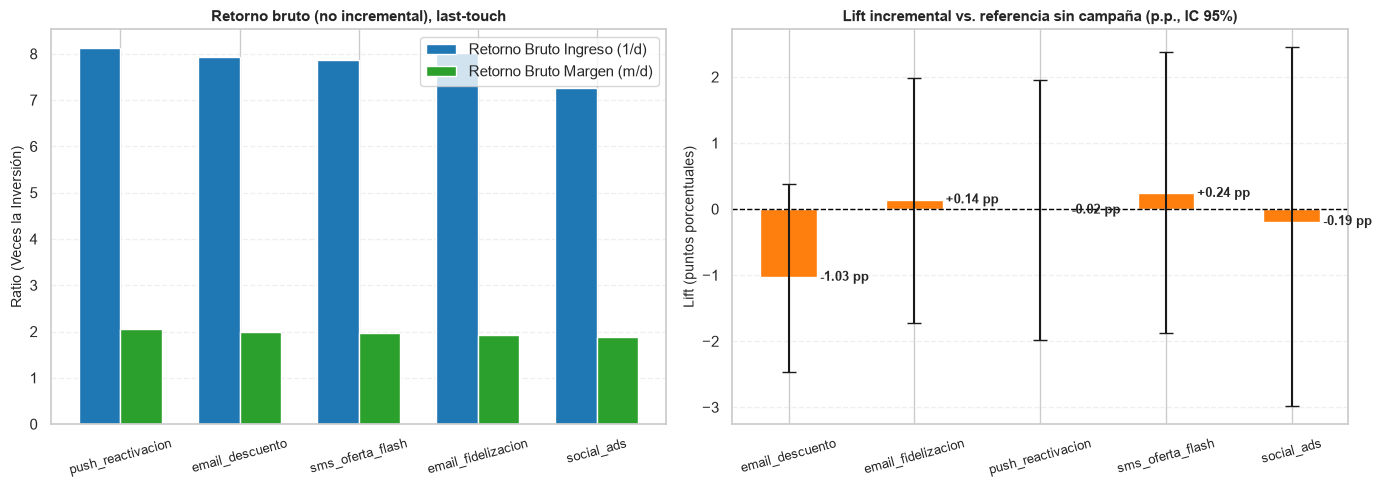

In [20]:
# Gráfica Comparativa: Retorno Bruto (Contable) vs Lift Incremental
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Retorno Bruto
x = np.arange(len(roi_tipo))
width = 0.35
ax1.bar(x - width/2, roi_tipo['retorno_bruto_ingreso'], width, label='Retorno Bruto Ingreso (1/d)', color='#1F77B4')
ax1.bar(x + width/2, roi_tipo['retorno_bruto_margen'], width, label='Retorno Bruto Margen (m/d)', color='#2CA02C')
ax1.set_title('Retorno bruto (no incremental), last-touch', fontsize=11, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(roi_tipo['tipo_campana'], fontsize=9, rotation=15)
ax1.set_ylabel('Ratio (Veces la Inversión)', fontsize=10)
ax1.grid(axis='y', alpha=0.3, linestyle='--')
ax1.legend(frameon=True)

# Subplot 2: Lift incremental por tipo con IC 95% bootstrap
lt = df_lift_tipo[df_lift_tipo['tipo_campana'] != 'TOTAL'].reset_index(drop=True)
err = np.array([lt['lift_pp'] - lt['ic_lift'].str[0], lt['ic_lift'].str[1] - lt['lift_pp']])
x2 = np.arange(len(lt))
ax2.bar(x2, lt['lift_pp'], color='#FF7F0E', width=0.45, yerr=err, capsize=5)
ax2.axhline(0, color='black', lw=1.0, linestyle='--')
ax2.set_title('Lift incremental vs. referencia sin campaña (p.p., IC 95%)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Lift (puntos porcentuales)', fontsize=10)
ax2.set_xticks(x2)
ax2.set_xticklabels(lt['tipo_campana'], fontsize=9, rotation=15)
ax2.grid(axis='y', alpha=0.3, linestyle='--')

for i, v in enumerate(lt['lift_pp']):
    ax2.annotate(f"{v:+.2f} pp", (i + 0.25, v), ha='left', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


---
## Resumen Ejecutivo de A4 (Variables Dinámicas para el Dashboard A5)

A continuación se sintetizan las métricas corporativas de marketing calculadas enteramente mediante variables dinámicas para asegurar la consistencia y reproducibilidad en A5.


In [21]:
# Tabla resumen ejecutivo enteramente gobernada por variables calculadas (R1, R3, C17)
retorno_bruto_ingreso_global = monto_atribuido_lt / costo_estimado_lt
retorno_bruto_margen_global = margen_atribuido_lt / costo_estimado_lt

resumen_a4 = pd.DataFrame({
    'Dimensión / Métrica Publicitaria': [
        'Total Campañas Enviadas',
        'Campañas Elegibles Ventana Completa (< 2024-12-01)',
        'Tasa de Conversión Declarada Global (%)',
        'Tasa de Conversión Validada 30d (%)',
        'Conversión Declarada: 2023-S1 vs 2024-S2',
        'Variación Relativa de la Conversión (primer vs último semestre)',
        'Transacciones Atribuidas (Last-Touch Deduplicado)',
        'Monto Total de Ventas Atribuidas a Campañas ($)',
        'Margen Bruto Total Atribuido a Campañas ($)',
        'Costo Único Estimado en Descuentos de Campaña ($)',
        'Retorno Bruto Global de Ingreso (Identidad Contable)',
        'Retorno Bruto Global de Margen (Identidad Contable)',
        'Tasa de Compra: Referencia sin Campaña vs Post-Envío (30d)',
        'Lift Incremental Global de Compra (30d, vs. mismo cliente sin campaña)',
        'IC 95% Bootstrap Lift Incremental (Cliente)',
        'ROI Incremental Global Estimado',
        'IC 95% Bootstrap ROI Incremental',
        'Efecto Lift Calendario (Controles Mismo Período)',
        'Contraste Descuentos 20% vs 25% (Rendimiento)',
        'Fricción CRM: No Convertidores vs Convertidores'
    ],
    'Valor Dinámico': [
        f"{len(campanas):,} envíos",
        f"{len(camp_elegible):,} envíos",
        f"{campanas['convertido'].mean()*100:.2f}%",
        f"{campanas['convertido_validado_30d'].mean()*100:.2f}%",
        f"{decl_s1:.1f}% ➔ {decl_s4:.1f}%",
        f"Declarada {caida_relativa:+.1f}%; validada {caida_relativa_val:+.1f}% ({caida_relativa_valc:+.1f}% con ventana completa); enunciado {caida_enunciado:+.0f}%",
        f"{n_tx_unicas:,} compras ({n_tx_multi_campana:,} estaban en más de una campaña; {tx_eliminadas:,} asignaciones duplicadas eliminadas)",
        f"${monto_atribuido_lt:,.2f}",
        f"${margen_atribuido_lt:,.2f}",
        f"${costo_estimado_lt:,.2f}",
        f"{retorno_bruto_ingreso_global:.2f}x (refleja 1/d medio)",
        f"{retorno_bruto_margen_global:.2f}x (refleja m/d medio)",
        f"{tasa_pre_base:.2f}% (referencia) vs {tasa_post_base:.2f}% (post)",
        f"{lift_global_pp:+.2f} p.p." + (" (no se detecta efecto incremental)" if ic_lift_global[0] <= 0 <= ic_lift_global[1] else ""),
        f"[{ic_lift_global[0]:+.2f}, {ic_lift_global[1]:+.2f}] p.p." + (" (incluye 0)" if ic_lift_global[0] <= 0 <= ic_lift_global[1] else " (no incluye 0)"),
        f"{roi_incremental_global:.2f} (margen incremental ${margen_incremental:,.2f} frente a costo ${costo_unico:,.2f})",
        f"[{ic_roi_global[0]:.2f}, {ic_roi_global[1]:.2f}]" + (" (incluye 0)" if ic_roi_global[0] <= 0 <= ic_roi_global[1] else " (no incluye 0)")
            + ("; incluye −1: margen incremental cero" if ic_roi_global[0] <= -1 <= ic_roi_global[1] else ""),
        f"{lift_calendario:+.2f} p.p. (IC: [{ic_lift_cal[0]:+.2f}, {ic_lift_cal[1]:+.2f}]"
            + (", incluye 0)" if ic_lift_cal[0] <= 0 <= ic_lift_cal[1] else ", no incluye 0)"),
        f"Bruto {tasa_20:.2f}% vs {tasa_25:.2f}%; ajustado OR 25%/20% = {or_25_20:.2f} (p={p_25_20_aj:.3f})"
            + (" → diferencia significativa" if p_25_20_aj < 0.05 else " → rendimientos decrecientes posibles, no concluyente"),
        f"Quejas {friccion_test.loc[0, 'Nunca convirtieron (%)']:.1f}% vs {friccion_test.loc[0, 'Sí convirtieron (%)']:.1f}% (p={friccion_test.loc[0, 'p (z)']:.3f}); "
        f"no resueltas {friccion_test.loc[1, 'Nunca convirtieron (%)']:.1f}% vs {friccion_test.loc[1, 'Sí convirtieron (%)']:.1f}% (p={friccion_test.loc[1, 'p (z)']:.3f}); "
        f"devoluciones {friccion_test.loc[2, 'Nunca convirtieron (%)']:.1f}% vs {friccion_test.loc[2, 'Sí convirtieron (%)']:.1f}% (p={friccion_test.loc[2, 'p (z)']:.3f})"
        + (" → sin diferencia significativa" if not hay_diferencia_friccion else " → hay diferencias significativas")
    ]
})

print("TABLA CONSOLIDADA EJECUTIVA A4 (GOBERNADA POR VARIABLES DINÁMICAS):")
with pd.option_context('display.max_colwidth', None):
    display(resumen_a4)


TABLA CONSOLIDADA EJECUTIVA A4 (GOBERNADA POR VARIABLES DINÁMICAS):


,Dimensión / Métrica Publicitaria,Valor Dinámico
0,Total Campañas Enviadas,"8,820 envíos"
1,Campañas Elegibles Ventana Completa (< 2024-12-01),"8,450 envíos"
2,Tasa de Conversión Declarada Global (%),9.04%
3,Tasa de Conversión Validada 30d (%),2.03%
4,Conversión Declarada: 2023-S1 vs 2024-S2,11.8% ➔ 6.4%
5,Variación Relativa de la Conversión (primer vs último semestre),Declarada -46.0%; validada -55.5% (-50.4% con ventana completa); enunciado -50%
6,Transacciones Atribuidas (Last-Touch Deduplicado),"2,122 compras (54 estaban en más de una campaña; 54 asignaciones duplicadas eliminadas)"
7,Monto Total de Ventas Atribuidas a Campañas ($),"$716,645.40"
8,Margen Bruto Total Atribuido a Campañas ($),"$179,403.17"
9,Costo Único Estimado en Descuentos de Campaña ($),"$90,682.05"
